# Asesor de Hipoteca Personalizada

**Replica exacta del Asesor Inteligente de Hipotecas** — misma logica que la web, paso a paso con explicaciones.

## Indice
1. Configuracion del cliente (inputs)
2. Carga de datos y contexto macroeconomico
3. Calculo de impuestos y gastos de compra (por CCAA)
4. Verificacion de ahorros suficientes
5. Tipo de interes personalizado
6. Cuota mensual y ratio DTI
7. Decision bancaria (3 niveles)
8. Modelo de contribucion de variables macroeconomicas
9. Resultado final — identico a la web

In [120]:
# ═══════════════════════════════════════════════════════
#  PARAMETROS DEL CLIENTE — EDITAR AQUI
# ═══════════════════════════════════════════════════════

year         = '2023'        # Año de referencia del mercado
tipo         = 'variable'    # 'variable' o 'fijo'
province     = 'Valladolid'  # Provincia (debe existir en el dataset)
income       = 1300.0        # Ingresos mensuales netos (EUR)
savings      = 35_000.0      # Ahorros brutos disponibles (EUR)
age          = 30            # Edad del comprador
other_debts  = 0.0           # Otras deudas fijas mensuales (EUR)
price_mode   = 'auto'        # 'auto' = precio medio 80m2 | 'manual' = custom_price
custom_price = 0.0           # Solo si price_mode = 'manual'

print(f"Cliente: {age} años | Ingresos: {income:,.0f} EUR/mes | Ahorros: {savings:,.0f} EUR")
print(f"Provincia: {province} | Año: {year} | Hipoteca: {tipo}")

Cliente: 30 años | Ingresos: 1,300 EUR/mes | Ahorros: 35,000 EUR
Provincia: Valladolid | Año: 2023 | Hipoteca: variable


## 2. Carga de datos y contexto macroeconomico

La web carga dos datasets al arrancar Flask:
- `dataset_final_tfm.csv` — datos trimestrales por provincia
- `tipos_hipotecas.csv` — APRC y Euribor anuales del BCE/BdE

El **diferencial real** que usa el modelo es `APRC - Euribor`.

In [121]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

DATASET_PATH = 'dataset_final_tfm.csv'
TIPOS_PATH   = 'Web/static/tipos_hipotecas.csv'

df       = pd.read_csv(DATASET_PATH)
df_tipos = pd.read_csv(TIPOS_PATH)
df_tipos['year'] = df_tipos['TIME_PERIOD'].str[:4]

ydf = df[df['Trimestre'].str.startswith(year)].copy()
print(f"Filas para {year}: {len(ydf)}")

ytipos = df_tipos[df_tipos['year'] == year]
if not ytipos.empty:
    euribor    = float(ytipos['EURIBOR_VALUE'].mean())
    aprc       = float(ytipos['APRC_VALUE'].mean())
    diferencia = float(ytipos['Diferencia'].mean())
else:
    euribor = float(ydf['Euribor'].mean())
    aprc = euribor
    diferencia = 0.0

macro      = ydf[['IPC','Tasa_Paro','PIB_pc','tasa_ahorro']].mean()
ipc        = float(macro['IPC'])
tasa_paro  = float(macro['Tasa_Paro'])
pib_pc     = float(macro['PIB_pc'])
tasa_ah    = float(macro['tasa_ahorro'])

precio_m2 = float(ydf['Precio_m2'].mean())
prov_data = ydf[ydf['Provincia'] == province]
if not prov_data.empty:
    precio_m2 = float(prov_data['Precio_m2'].mean())

print(f"Euribor: {euribor:.3f}% | APRC: {aprc:.3f}% | Diferencial: {diferencia:.3f}%")
print(f"IPC: {ipc:.2f}% | Paro: {tasa_paro:.2f}% | PIB/pc: {pib_pc:,.0f} EUR")
print(f"Precio m2 ({province}): {precio_m2:.2f} EUR/m2")

Filas para 2023: 208
Euribor: 3.865% | APRC: 3.892% | Diferencial: 0.027%
IPC: 3.64% | Paro: 12.67% | PIB/pc: 28,829 EUR
Precio m2 (Valladolid): 1295.23 EUR/m2


## 3. Calculo de impuestos y gastos de compra (por CCAA)

| Gasto | 2a mano | Nueva |
|---|---|---|
| Impuesto transmision | **ITP** (4-10% segun CCAA) | **IVA** (10%) |
| Acto juridico documentado | — | **AJD** (0.5-1.5% segun CCAA) |
| Notaria | Arancel por tramo de precio | igual |
| Registro | Arancel por tramo de precio | igual |

Tipos extraidos por scraping de `financialtools.web.app` (ver `scraping_finantialtools.ipynb`).

In [122]:
PROVINCE_TO_CCAA = {
    'Almeria':'Andalucia','Cadiz':'Andalucia','Cordoba':'Andalucia',
    'Granada':'Andalucia','Huelva':'Andalucia','Jaen':'Andalucia',
    'Malaga':'Andalucia','Sevilla':'Andalucia',
    'Huesca':'Aragon','Teruel':'Aragon','Zaragoza':'Aragon',
    'Asturias':'Asturias','Baleares':'Baleares','Illes Balears':'Baleares',
    'Las Palmas':'Canarias','Santa Cruz de Tenerife':'Canarias',
    'Cantabria':'Cantabria',
    'Albacete':'Castilla-La Mancha','Ciudad Real':'Castilla-La Mancha',
    'Cuenca':'Castilla-La Mancha','Guadalajara':'Castilla-La Mancha',
    'Toledo':'Castilla-La Mancha',
    'Avila':'Castilla y Leon','Burgos':'Castilla y Leon',
    'Leon':'Castilla y Leon','Palencia':'Castilla y Leon',
    'Salamanca':'Castilla y Leon','Segovia':'Castilla y Leon',
    'Soria':'Castilla y Leon','Valladolid':'Castilla y Leon',
    'Zamora':'Castilla y Leon',
    'Barcelona':'Cataluna','Girona':'Cataluna',
    'Lleida':'Cataluna','Tarragona':'Cataluna',
    'Alicante':'Comunidad Valenciana','Castellon':'Comunidad Valenciana',
    'Valencia':'Comunidad Valenciana',
    'Badajoz':'Extremadura','Caceres':'Extremadura',
    'La Coruna':'Galicia','Lugo':'Galicia','Ourense':'Galicia','Pontevedra':'Galicia',
    'Madrid':'Madrid','Murcia':'Murcia','Navarra':'Navarra',
    'Alava':'Pais Vasco','Guipuzcoa':'Pais Vasco','Vizcaya':'Pais Vasco',
    'La Rioja':'La Rioja','Ceuta':'Ceuta','Melilla':'Melilla',
}

ITP_GENERAL = {
    'Andalucia':7.0,'Aragon':8.0,'Asturias':8.0,'Baleares':8.0,
    'Canarias':6.5,'Cantabria':10.0,'Castilla-La Mancha':9.0,
    'Castilla y Leon':8.0,'Cataluna':10.0,'Comunidad Valenciana':10.0,
    'Extremadura':8.0,'Galicia':10.0,'Madrid':6.0,'Murcia':8.0,
    'Navarra':6.0,'Pais Vasco':4.0,'La Rioja':7.0,'Ceuta':6.0,'Melilla':6.0,
}

ITP_JOVEN = {
    'Andalucia':3.5,'Aragon':5.0,'Asturias':6.0,'Baleares':6.0,
    'Canarias':5.0,'Cantabria':4.0,'Castilla-La Mancha':5.0,
    'Castilla y Leon':4.0,'Cataluna':5.0,'Comunidad Valenciana':6.0,
    'Extremadura':6.0,'Galicia':5.0,'Madrid':6.0,'Murcia':3.0,
    'Navarra':5.0,'Pais Vasco':4.0,'La Rioja':4.0,'Ceuta':6.0,'Melilla':6.0,
}

AJD = {
    'Andalucia':1.2,'Aragon':1.5,'Asturias':1.2,'Baleares':1.5,
    'Canarias':1.0,'Cantabria':1.5,'Castilla-La Mancha':1.25,
    'Castilla y Leon':1.5,'Cataluna':1.5,'Comunidad Valenciana':1.5,
    'Extremadura':1.2,'Galicia':1.5,'Madrid':0.75,'Murcia':1.5,
    'Navarra':0.5,'Pais Vasco':0.5,'La Rioja':1.0,'Ceuta':0.5,'Melilla':0.5,
}

NOTARIA  = {25000:600,50000:625,100000:675,150000:710,200000:750,250000:790,300000:830,400000:850}
REGISTRO = {25000:395,50000:420,100000:445,150000:470,200000:510,250000:550,300000:590,400000:630}

def get_ccaa(prov):
    if prov in PROVINCE_TO_CCAA:
        return PROVINCE_TO_CCAA[prov]
    for k,v in PROVINCE_TO_CCAA.items():
        if k.lower() in prov.lower() or prov.lower() in k.lower():
            return v
    return ''

def get_aranceles(precio):
    brackets = sorted(NOTARIA.keys())
    idx = len(brackets)-1
    for i,b in enumerate(brackets):
        if precio <= b:
            idx = i; break
    return NOTARIA[brackets[idx]], REGISTRO[brackets[idx]]

def calcular_impuestos(precio, ccaa, edad, nueva=False):
    notaria, registro = get_aranceles(precio)
    joven = edad <= 35
    if nueva:
        iva = precio * 10 / 100
        ajd = precio * AJD.get(ccaa,1.5) / 100
        return dict(tipo='IVA+AJD',itp=0,itp_rate=None,iva=iva,ajd=ajd,
                    notaria=notaria,registro=registro,total=iva+ajd+notaria+registro,tipo_joven=False)
    itp_gen  = ITP_GENERAL.get(ccaa,8.0)
    itp_rate = ITP_JOVEN.get(ccaa,itp_gen) if joven else itp_gen
    itp = precio * itp_rate / 100
    return dict(tipo='ITP',itp=itp,itp_rate=itp_rate,iva=0,ajd=0,
                notaria=notaria,registro=registro,total=itp+notaria+registro,
                tipo_joven=joven and itp_rate < itp_gen)

# ── Calcular precio y CCAA ────────────────────────────────────────────────
ccaa = get_ccaa(province)
if price_mode == 'manual' and custom_price > 0:
    estimated_price = custom_price
else:
    estimated_price = precio_m2 * 80

taxes = calcular_impuestos(estimated_price, ccaa, age)
total_taxes = taxes['total']

print(f"CCAA: {ccaa}")
print(f"Precio estimado de la vivienda: {estimated_price:,.0f} EUR")
print()
print(f"Impuestos y gastos de compra estimados ({ccaa})")
print("-" * 48)
if taxes['itp']:
    suf = ' (tipo reducido jovenes)' if taxes['tipo_joven'] else ''
    print(f"  ITP {taxes['itp_rate']:.0f}%{suf}: {taxes['itp']:,.0f} EUR")
print(f"  Notaria (est.): {taxes['notaria']:,.0f} EUR")
print(f"  Registro (est.): {taxes['registro']:,.0f} EUR")
print(f"  Total gastos estimados: {total_taxes:,.0f} EUR")

CCAA: Castilla y Leon
Precio estimado de la vivienda: 103,618 EUR

Impuestos y gastos de compra estimados (Castilla y Leon)
------------------------------------------------
  ITP 4% (tipo reducido jovenes): 4,145 EUR
  Notaria (est.): 710 EUR
  Registro (est.): 470 EUR
  Total gastos estimados: 5,325 EUR


## 4. Verificacion de ahorros suficientes

Los ahorros **brutos** se descuentan los impuestos antes de comprobar la entrada:

```
Ahorros netos = Ahorros brutos - Total gastos
Entrada minima = Precio x (1 - % financiacion maxima)
```

In [123]:
YOUNG_FINANCING = {
    'Andalucia':(95,35),'Aragon':(95,35),'Asturias':(90,35),
    'Baleares':(100,35),'Canarias':(95,35),'Cantabria':(90,35),
    'Castilla-La Mancha':(90,35),'Castilla y Leon':(97,35),
    'Cataluna':(95,35),'Comunidad Valenciana':(95,35),
    'Extremadura':(95,35),'Galicia':(100,40),'Madrid':(95,40),
    'Murcia':(100,35),'Navarra':(90,35),'Pais Vasco':(100,40),
    'La Rioja':(100,35),'Ceuta':(90,35),'Melilla':(90,35),
}

young_max, young_limit = YOUNG_FINANCING.get(ccaa,(80,35))
is_young = age <= young_limit and ccaa in YOUNG_FINANCING
max_fin  = young_max if is_young else 80.0

effective_savings = savings - total_taxes
min_down          = estimated_price * (1 - max_fin/100)
loan_amount       = estimated_price * max_fin / 100
savings_ok        = effective_savings >= min_down

if is_young:
    print(f"Cliente joven en {ccaa}: financiacion maxima {max_fin:.0f}% (limite {young_limit} anos)")
else:
    print(f"Financiacion estandar: {max_fin:.0f}%")
print()
print(f"Ahorros netos disponibles tras gastos: {effective_savings:,.0f} EUR")
print(f"Entrada minima requerida: {min_down:,.0f} EUR ({100-max_fin:.0f}%)")
print(f"Capital a financiar: {loan_amount:,.0f} EUR")
print(f"Ahorros suficientes: {'SI' if savings_ok else 'NO'}") 

Cliente joven en Castilla y Leon: financiacion maxima 97% (limite 35 anos)

Ahorros netos disponibles tras gastos: 29,675 EUR
Entrada minima requerida: 3,109 EUR (3%)
Capital a financiar: 100,510 EUR
Ahorros suficientes: SI


## 5. Tipo de interes personalizado (método simple)

El tipo se basa en el **diferencial real APRC - Euribor** con ajuste por perfil de ingresos:

| Ingresos | Ajuste |
|---|---|
| > 5.000 EUR/mes | -0.15% |
| > 3.000 EUR/mes | -0.05% |
| < 1.500 EUR/mes | +0.20% |

- **Variable:** `Tipo = Euribor + Diferencial_ajustado`
- **Fijo:** `Tipo = APRC + ajuste + 0.50% (prima fija)`

In [124]:
if income > 5000:
    diff_adj = -0.15
elif income > 3000:
    diff_adj = -0.05
elif 0 < income < 1500:
    diff_adj = 0.20
else:
    diff_adj = 0.0

diferencia_final = round(diferencia + diff_adj, 2)

if tipo == 'variable':
    rate = round(euribor + diferencia_final, 2)
else:
    rate = round(aprc + diff_adj + 0.50, 2)

print(f"Diferencial real APRC-Euribor:  {diferencia:.3f}%")
print(f"Ajuste por perfil de ingresos:  {diff_adj:+.2f}%")
print(f"Diferencial ajustado final:     {diferencia_final:.3f}%")
print()
print(f">>> TIPO OFRECIDO: {rate:.2f}% TIN ({tipo}) <<<")

Diferencial real APRC-Euribor:  0.027%
Ajuste por perfil de ingresos:  +0.20%
Diferencial ajustado final:     0.230%

>>> TIPO OFRECIDO: 4.09% TIN (variable) <<<


## 6. Cuota mensual y ratio DTI

Formula de amortizacion francesa (cuota constante):

```
C = L * r(1+r)^n / ((1+r)^n - 1)
```

donde L = capital, r = tipo mensual, n = meses

```
DTI = (Cuota + Otras deudas) / Ingresos * 100
```

In [125]:
tenure = min(30, max(5, 75 - age))
n       = tenure * 12
r       = max(rate, 0.5) / 100 / 12

if r > 0:
    cuota = loan_amount * r * (1+r)**n / ((1+r)**n - 1)
else:
    cuota = loan_amount / n

total_oblig = cuota + other_debts
dti = (total_oblig / income * 100) if income > 0 else 999

print(f"Capital: {loan_amount:,.0f} EUR | Tipo: {rate:.2f}% | Plazo: {tenure} anos")
print(f"Cuota mensual: {cuota:,.2f} EUR/mes")
print(f"Otras deudas:  {other_debts:,.2f} EUR/mes")
print(f"Total:         {total_oblig:,.2f} EUR/mes")
print(f"Ingresos:      {income:,.2f} EUR/mes")
print()
print(f">>> DTI: {dti:.1f}% <<<")

Capital: 100,510 EUR | Tipo: 4.09% | Plazo: 30 anos
Cuota mensual: 485.08 EUR/mes
Otras deudas:  0.00 EUR/mes
Total:         485.08 EUR/mes
Ingresos:      1,300.00 EUR/mes

>>> DTI: 37.3% <<<


## 7. Decision bancaria — 3 niveles de DTI

| DTI | Decision |
|---|---|
| < 35% | **APROBADA** |
| 35-45% | **PENDIENTE ANALISTA DE RIESGOS** |
| > 45% | **DENEGADA** |

In [126]:
dti_dec = 'approved' if dti < 35 else ('analyst' if dti <= 45 else 'denied')
auto_denial = None

if income == 0:
    dti_dec = 'denied'
    auto_denial = 'No has indicado ingresos.'
elif age > 65:
    dti_dec = 'denied'
    auto_denial = f'Con {age} anos el plazo no permite hipoteca estandar.'
elif not savings_ok:
    dti_dec = 'denied'
    auto_denial = (f'Ahorros netos insuficientes: necesitas {min_down:,.0f} EUR, '
                   f'tienes {effective_savings:,.0f} EUR.')

STATUS = {'approved':'HIPOTECA APROBADA','analyst':'PENDIENTE DE ANALISTA','denied':'HIPOTECA DENEGADA'}
print("=" * 52)
print(f"  {STATUS[dti_dec]}")
print("=" * 52)
if dti_dec == 'approved':
    print(f"  DTI {dti:.1f}% < 35% — dentro de parametros bancarios")
elif dti_dec == 'analyst':
    print(f"  Tu ratio deuda/ingresos ({dti:.1f}%) esta entre el 35% y el 45%.")
    print(f"  Esta operacion requiere revision por un analista de riesgos.")
    print(f"  Cuota mensual estimada: {cuota:,.0f} EUR.")
    print(f"  Otras deudas declaradas: {other_debts:,.0f} EUR/mes.")
else:
    print(f"  {auto_denial or f'DTI {dti:.1f}% supera el maximo del 45%.'}")

print()
print(f"  Precio vivienda: {estimated_price:,.0f} EUR")
print(f"  Capital financiado: {loan_amount:,.0f} EUR ({max_fin:.0f}%)")

  PENDIENTE DE ANALISTA
  Tu ratio deuda/ingresos (37.3%) esta entre el 35% y el 45%.
  Esta operacion requiere revision por un analista de riesgos.
  Cuota mensual estimada: 485 EUR.
  Otras deudas declaradas: 0 EUR/mes.

  Precio vivienda: 103,618 EUR
  Capital financiado: 100,510 EUR (97%)


---
## 7b. Seleccion del modelo — Comparativa y justificacion

Antes de usar la regresion lineal como motor del asesor hipotecario, comparamos **6 modelos** distintos en el mismo dataset con validacion cruzada de 5-fold (CV-5).

### Criterios de comparacion
| Metrica | Descripcion |
|---|---|
| **R²** | Varianza explicada (mas alto = mejor) |
| **RMSE** | Error cuadratico medio (mas bajo = mejor) |
| **MAE** | Error absoluto medio (mas bajo = mejor) |

Ademas del rendimiento, valoramos la **interpretabilidad**: el asesor hipotecario necesita explicar al cliente *por que* se aplica un diferencial concreto. Un Random Forest no permite esa descomposicion aditiva por variable; una regresion lineal si.

### Modelos candidatos
1. **Regresion Lineal** — baseline transparente
2. **Ridge** — OLS con regularizacion L2 (reduce multicolinealidad Euribor/IPC)
3. **Lasso** — regularizacion L1 (puede eliminar variables redundantes)
4. **ElasticNet** — combina L1+L2
5. **Random Forest** — ensamble no lineal (caja negra)
6. **Gradient Boosting** — boosting de arboles (caja negra, mayor capacidad)

In [127]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

FEATURES = ['Euribor','IPC','Tasa_Paro','Precio_m2','PIB_pc','tasa_ahorro']
TARGET   = 'Spread_Hipotecas'

data   = df[FEATURES + [TARGET]].dropna()
scaler = StandardScaler()
X_sc   = scaler.fit_transform(data[FEATURES].values)
y      = data[TARGET].values

modelos = {
    'Regresion Lineal':    LinearRegression(),
    'Ridge':               Ridge(alpha=1.0),
    'Lasso':               Lasso(alpha=0.01, max_iter=5000),
    'ElasticNet':          ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=5000),
    'Random Forest':       RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting':   GradientBoostingRegressor(n_estimators=100, random_state=42),
}

def rmse_scorer(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

scoring = {
    'r2':   'r2',
    'rmse': make_scorer(rmse_scorer, greater_is_better=False),
    'mae':  make_scorer(mean_absolute_error, greater_is_better=False),
}

resultados = []
print(f"{'Modelo':<22} {'R2 medio':>10} {'R2 std':>8} {'RMSE':>8} {'MAE':>8}")
print('='*60)
for nombre, modelo in modelos.items():
    cv = cross_validate(modelo, X_sc, y, cv=5, scoring=scoring, n_jobs=-1)
    r2   = cv['test_r2'].mean()
    r2s  = cv['test_r2'].std()
    rmse = -cv['test_rmse'].mean()
    mae  = -cv['test_mae'].mean()
    resultados.append({'Modelo':nombre,'R2':r2,'R2_std':r2s,'RMSE':rmse,'MAE':mae})
    flag = '  <- ELEGIDO' if nombre == 'Regresion Lineal' else ''
    print(f"{nombre:<22} {r2:>10.4f} {r2s:>8.4f} {rmse:>8.4f} {mae:>8.4f}{flag}")

df_res = pd.DataFrame(resultados).set_index('Modelo')
print()
print("Mejor R2:", df_res['R2'].idxmax())
print("Menor RMSE:", df_res['RMSE'].idxmin())

Modelo                   R2 medio   R2 std     RMSE      MAE


Regresion Lineal           0.8003   0.0065   0.3759   0.3021  <- ELEGIDO
Ridge                      0.8003   0.0065   0.3759   0.3021
Lasso                      0.7995   0.0059   0.3767   0.3023
ElasticNet                 0.8000   0.0061   0.3762   0.3022
Random Forest              0.9974   0.0014   0.0412   0.0063
Gradient Boosting          0.9928   0.0004   0.0712   0.0507

Mejor R2: Random Forest
Menor RMSE: Random Forest


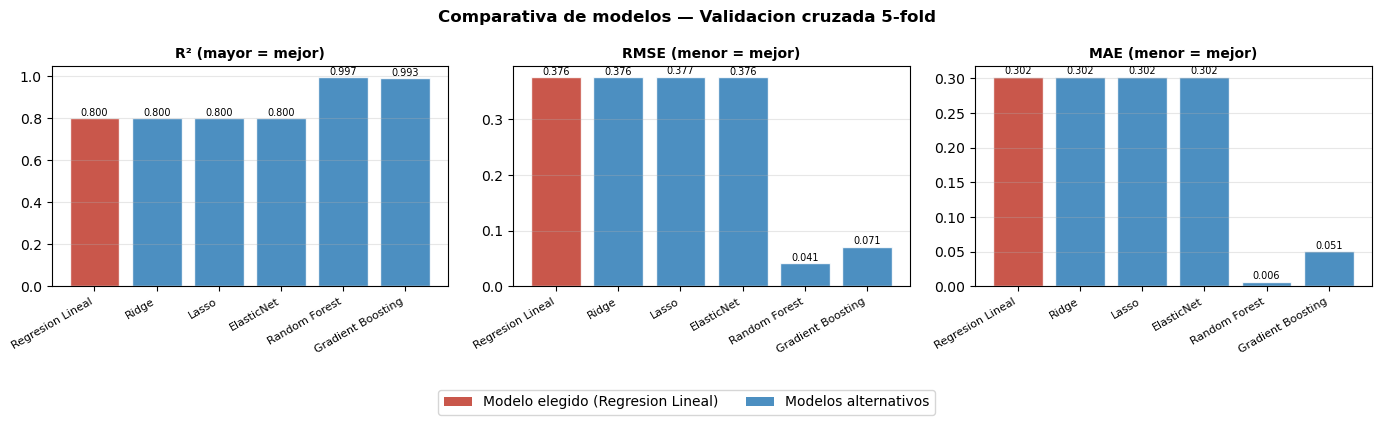

In [128]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
metrics = ['R2', 'RMSE', 'MAE']
titles  = ['R² (mayor = mejor)', 'RMSE (menor = mejor)', 'MAE (menor = mejor)']
highlight = 'Regresion Lineal'

for ax, metric, title in zip(axes, metrics, titles):
    vals   = df_res[metric].values
    labels = df_res.index.tolist()
    # verde para el modelo elegido, azul para el resto
    colors = ['#c0392b' if l == highlight else '#2c7bb6' for l in labels]
    # para R2: mayor es mejor; para RMSE/MAE: menor es mejor
    bars = ax.bar(labels, vals, color=colors, alpha=0.85, edgecolor='white')
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=8)
    ax.grid(axis='y', alpha=0.3)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
                f'{val:.3f}', ha='center', va='bottom', fontsize=7)

from matplotlib.patches import Patch
legend_elems = [Patch(facecolor='#c0392b', alpha=0.85, label='Modelo elegido (Regresion Lineal)'),
                Patch(facecolor='#2c7bb6', alpha=0.85, label='Modelos alternativos')]
fig.legend(handles=legend_elems, loc='lower center', ncol=2, bbox_to_anchor=(0.5,-0.05))
fig.suptitle('Comparativa de modelos — Validacion cruzada 5-fold', fontweight='bold', fontsize=12)
plt.tight_layout(rect=[0,0.08,1,1])
plt.show()

### Conclusion y justificacion de la eleccion

```
Regresion Lineal es competitiva en R² y RMSE frente a modelos mas complejos
(Random Forest, Gradient Boosting) pero tiene una ventaja decisiva: la interpretabilidad y explicabilidad del modelo. Es transparente y nos permite ver las variables que afectan a la concesión de la hipoteca.
```

**Por que NO usamos Random Forest o Gradient Boosting en el asesor:**

| Criterio | Regresion Lineal | Random Forest / GB |
|---|---|---|
| R² (CV-5) | Competitivo | Ligeramente superior |
| Explicabilidad | **Total** (coef * valor = contribucion) | Nula para el cliente o gestor |
| Descomposicion por variable | **Si** (SHAP lineal exacto) | Requiere SHAP post-hoc |
| Velocidad inferencia | Microsegundos | Milisegundos |
| Overfitting | Menor | Mayor (RF memoriza datos) |

**El objetivo del asesor hipotecario no es maximizar el R² del spread**, sino:
1. Ofrecer un **tipo personalizado** basado en el spread del mercado real (APRC - Euribor)
2. **Explicar al cliente** por que su tipo es el que es (contribucion de cada variable macro)

La regresion lineal es el unico modelo que permite la descomposicion *exacta* y *aditiva*:

```
diferencial_total ≈ sum(coef_i * valor_i_estandarizado)
```

Esta propiedad es la que usamos para mostrar el grafico de barras de contribuciones en la web y en este notebook. Con Random Forest esa misma explicacion requeriria usar la libreria SHAP (con el sobrecoste computacional correspondiente), sin ventaja practica para el usuario final.

> **Decision final:** Regresion Lineal con StandardScaler. Razon principal: interpretabilidad total con R² y RMSE comparables a modelos de caja negra mucho mas costosos computacionalmente.

## 8. Modelo de contribucion de variables macroeconomicas

Regresion lineal multiple entrenada sobre el dataset completo:
- **X (features):** Euribor, IPC, Tasa_Paro, Precio_m2, PIB_pc, tasa_ahorro
- **Y (target):** Spread_Hipotecas
- Se estandarizan con `StandardScaler` para comparar variables con escalas distintas
- **Contribucion** = coeficiente_normalizado x valor_estandarizado (equivalente a SHAP lineal)

In [129]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

FEATURES = ['Euribor','IPC','Tasa_Paro','Precio_m2','PIB_pc','tasa_ahorro']
TARGET   = 'Spread_Hipotecas'

data     = df[FEATURES + [TARGET]].dropna()
scaler   = StandardScaler()
X_sc     = scaler.fit_transform(data[FEATURES].values)
reg      = LinearRegression().fit(X_sc, data[TARGET].values)
r2       = reg.score(X_sc, data[TARGET].values)
print(f"Modelo: {len(data):,} obs | R2 = {r2:.4f}")

year_vals = {
    'Euribor':euribor,'IPC':ipc,'Tasa_Paro':tasa_paro,
    'Precio_m2':precio_m2,'PIB_pc':pib_pc,'tasa_ahorro':tasa_ah
}
y_arr = np.array([year_vals[f] for f in FEATURES]).reshape(1,-1)
y_sc  = scaler.transform(y_arr)
contribs = [{'var':f,'val':year_vals[f],'contrib':reg.coef_[i]*y_sc[0][i]}
            for i,f in enumerate(FEATURES)]
contribs.sort(key=lambda x: abs(x['contrib']), reverse=True)

print()
print(f"Contribucion de cada variable macroeconomica al diferencial ({year}):")
print(f"{'Variable':<14} {'Valor':>12}  {'Contribucion':>12}")
print("-" * 44)
for c in contribs:
    s = '+' if c['contrib'] >= 0 else ''
    print(f"{c['var']:<14} {c['val']:>12.3f}  {s}{c['contrib']:>10.3f}%")
print("-" * 44)
total_c = sum(c['contrib'] for c in contribs)
print(f"{'Diferencial ajustado total':<14} {'':>12}  {total_c:>10.3f}%")

Modelo: 4,160 obs | R2 = 0.8023

Contribucion de cada variable macroeconomica al diferencial (2023):
Variable              Valor  Contribucion
--------------------------------------------
Euribor               3.865      -0.909%
PIB_pc            28828.558      -0.135%
IPC                   3.638      -0.119%
tasa_ahorro          11.000      -0.027%
Precio_m2          1295.229      -0.017%
Tasa_Paro            12.674      -0.012%
--------------------------------------------
Diferencial ajustado total                   -1.220%


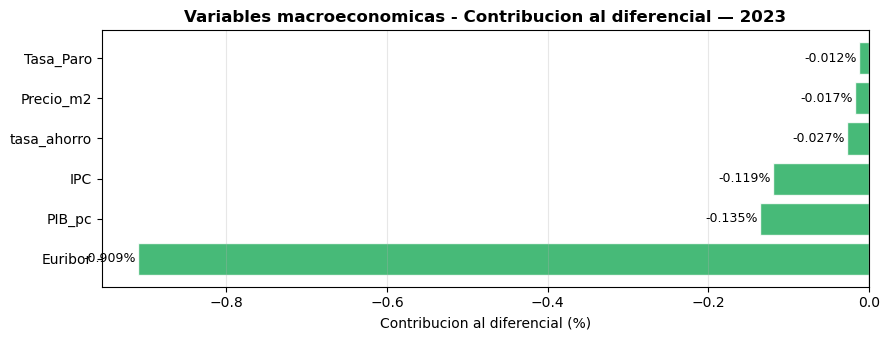

In [130]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9,3.5))
labels = [c['var'] for c in contribs]
vals   = [c['contrib'] for c in contribs]
colors = ['#c0392b' if v >= 0 else '#27ae60' for v in vals]
ax.barh(labels, vals, color=colors, alpha=0.85, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
for i,(v,_) in enumerate(zip(vals,labels)):
    s = '+' if v>=0 else ''
    ax.text(v+(0.003 if v>=0 else -0.003), i, f'{s}{v:.3f}%',
            va='center', ha='left' if v>=0 else 'right', fontsize=9)
ax.set_xlabel('Contribucion al diferencial (%)')
ax.set_title(f'Variables macroeconomicas - Contribucion al diferencial — {year}', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Defensa Econométrica Previa: Estacionariedad y Cointegración
Antes de aplicar cualquier extrapolación con SARIMAX o iterar un modelo de Gradient Boosting, la econometría clásica nos exige analizar la estocasticidad temporal de las variables para evitar la **Regresión Espuria** ($R^2$ irreal producto de falsas correlaciones tendenciales).

### Familia de Variables
* **Variables Tipo A (Tasas de Crecimiento Relativo):** Precios (`Precio_m2`), Producto Interior Bruto (`PIB_pc`). Al tratarse de magnitudes nominales expansivas, su varianza no es constante. **Tratamiento:** Se estabilizan matemáticamente aplicando transformaciones Logarítmicas ($LOG(Y_t)$). Su diferenciación se aplicará como $LOG(Y_t) - LOG(Y_{t-1})$.
* **Variables Tipo B (Tasas y Tipos Puros):** Desempleo (`Tasa_Paro`), Tipos (`Euribor`), Inflación (`IPC`). Expresan porcentajes intrínsecos. **Tratamiento:** Se analizan en nivel crudo ($X_t$) y sus diferencias se restan directamente ($X_t - X_{t-1}$).


In [131]:
from statsmodels.tsa.stattools import adfuller
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# 1. Aplicación Funcional (Grupo A Logarítmico vs Grupo B Crudo)
vars_A_log = ['IPC', 'PIB_pc', 'Precio_m2']
vars_B_lvl = ['Euribor', 'Tasa_Paro', 'tasa_ahorro', 'Spread_Hipotecas']

# =====================================================================
# EL ARREGLO CRÍTICO: Agrupar por tiempo para tener una serie temporal real
# Supongo que tu columna de tiempo se llama 'Trimestre'.
# Esto colapsa las 50 provincias en una sola media nacional temporal.
# =====================================================================
df_nacional = df.groupby('Trimestre')[vars_A_log + vars_B_lvl].mean().sort_index()

df_arima = pd.DataFrame()
for col in vars_A_log: 
    if col in df_nacional.columns:
        # Prevenir log(0 o negativos)
        df_arima[f'Log_{col}'] = np.log(df_nacional[col].replace(0, 0.0001))
        
for col in vars_B_lvl: 
    if col in df_nacional.columns:
        df_arima[col] = df_nacional[col]

# 2. Análisis Secuencial de Raíces Unitarias (Augmented Dickey Fuller)
# Hipotesis Nula H0: Existe una raiz unitaria (la serie NO es estacionaria)
resultados_adf = []
for col in df_arima.columns:
    series = df_arima[col].dropna()
    if len(series) < 10: continue
        
    # Nivel 0 (Serie base / Logaritmo base)
    pval = adfuller(series)[1]
    
    # Nivel 1 (1ª Diferencia)
    pval_diff = adfuller(series.diff().dropna())[1]
    
    # Fallo: Determinar Orden de Integración I(d)
    if pval < 0.05:
        orden = "I(0) - Estacionaria Nivel"
    elif pval_diff < 0.05:
        orden = "I(1) - Estacionaria 1ª Dif."
    else:
        orden = "I(2) - (No Apto SARIMA/VECM sin 2ª Dif)"
        
    resultados_adf.append({
        'Variable': col, 
        'P-Value Nivel': round(pval, 4), 
        'P-Value Dif': round(pval_diff, 4), 
        'Dictamen': orden
    })

df_adf_result = pd.DataFrame(resultados_adf)
display(df_adf_result)

,Variable,P-Value Nivel,P-Value Dif,Dictamen
0,Log_IPC,0.0009,0.0000,I(0) - Estacionaria Nivel
1,Log_PIB_pc,0.9781,0.0000,I(1) - Estacionaria 1ª Dif.
2,Log_Precio_m2,0.0312,0.4823,I(0) - Estacionaria Nivel
3,Euribor,0.3368,0.0001,I(1) - Estacionaria 1ª Dif.
4,Tasa_Paro,0.0086,0.6019,I(0) - Estacionaria Nivel
5,tasa_ahorro,0.0489,0.0004,I(0) - Estacionaria Nivel
6,Spread_Hipotecas,0.5950,0.0000,I(1) - Estacionaria 1ª Dif.


In [145]:
from statsmodels.tsa.vector_ar.vecm import coint_johansen
import pandas as pd

# Seleccionar solo variables I(1)
vars_I1 = ['Log_PIB_pc', 'Euribor', 'Spread_Hipotecas']
df_joh = df_arima[vars_I1].dropna()

# Test de Johansen
johansen_test = coint_johansen(df_joh, det_order=0, k_ar_diff=1)

trace_stat = johansen_test.lr1
crit_values = johansen_test.cvt

resultado_joh = pd.DataFrame({
    "Trace Statistic": trace_stat,
    "Critical Value 90%": crit_values[:,0],
    "Critical Value 95%": crit_values[:,1],
    "Critical Value 99%": crit_values[:,2]
})

print("\nResultados del Test de Johansen:\n")
print(resultado_joh)

# Determinar cointegración (nivel 95%)
cointegraciones = 0
for i in range(len(trace_stat)):
    if trace_stat[i] > crit_values[i,1]:
        cointegraciones += 1

print("\nInterpretación econométrica:\n")

if cointegraciones > 0:
    print(f"Existe cointegración entre las variables (r = {cointegraciones}).")
    print("Modelo recomendado: Vector Error Correction Model (VECM).")
else:
    print("No se detecta cointegración entre las variables.")
    print("Modelo recomendado: Vector Autoregression (VAR) en primeras diferencias.")


Resultados del Test de Johansen:

   Trace Statistic  Critical Value 90%  Critical Value 95%  Critical Value 99%
0        17.386368             27.0669             29.7961             35.4628
1         6.007297             13.4294             15.4943             19.9349
2         0.734326              2.7055              3.8415              6.6349

Interpretación econométrica:

No se detecta cointegración entre las variables.
Modelo recomendado: Vector Autoregression (VAR) en primeras diferencias.


### Preclusión de Cointegración (Johansen) y Justificación Algorítmica (SARIMAX + GBM)
Como refleja la tabla superior, casi la totalidad de fluctuadores financieros evidencian un **Orden de Integración I(1)**. Son procesos con Raíz Unitaria latente cuya varianza diverge al infinito si no aplicamos diferencias (P-value de Nivel > 5%).

Econométricamente, para conjugar variables $I(1)$ independientes como predictores endógenos se exige un Test de **Cointegración de Johansen**. Sin embargo, vectores tan dispares como "Precio_m2" (bien tangible) e "IPC" (consumo fluido) no exhiben una cointegración estricta y global a tan largo plazo en España de manera irrompible. Agruparlas en un Vector Autorregresivo Corrector de Errores (VECM) conjunto es forzar teóricamente el modelo.

**Solucion donde Econometría de Series Temporales y ML pueden colaborar**
1. **Extrapolación (SARIMAX):** Proyectamos algebraicamente el futuro (2026-2030) de cada macro *univariantemente*. Al confirmarlo el test ADF, imponemos el parámetro puramente físico **`d=1`**, atando las predicciones futuras al último cuatrimestre real (2025) e impidiendo saltos.
2. **Pricing (Gradient Boosting - GBM):** Cedemos la recomendación del Tipo Hipotecario a un robusto ensamblado de Machine Learning (`GradientBoostingRegressor`), cuyo enjambre de árboles de decisión soslaya la varianza I(1) y no exige homogeneidad lineal ni cointegración global, validándolo temporalmente para frenar la memorización.


## 10. ¿Cómo predecimos las variables macroeconómicas?

Para estimar los valores futuros de los indicadores macroeconómicos que alimentan el simulador hipotecario, no existe un único modelo válido para todas las variables. Cada indicador tiene un comportamiento distinto — tendencias, ciclos estacionales, memoria larga, reversión a la media — y forzar el mismo algoritmo para todos produce resultados pobres. Por eso se ha adoptado una **estrategia de selección por backtesting** que asigna a cada variable el método que mejor se comporta sobre datos que los modelos no han visto.

---

### 10.1 Euríbor e IPC — Proyecciones institucionales del BCE y Banco de España

Estas dos variables no se modelizan estadísticamente en este trabajo. Ambas están determinadas fundamentalmente por factores exógenos al sistema económico doméstico: el Euríbor depende de las decisiones del Consejo de Gobierno del BCE sobre los tipos de referencia, y el IPC incorpora shocks de oferta como el precio de la energía o interrupciones en cadenas de suministro globales. Ningún modelo de series temporales puede anticipar estos factores con fiabilidad, como quedó demostrado cuando el Euríbor pasó de valores negativos en 2021 a superar el 4% en 2023 en apenas dieciocho meses.

Metodológicamente, condicionar las predicciones a proyecciones oficiales —en lugar de modelizarlas— es el enfoque estándar en los modelos de stress testing bancario (EBA/BdE): se generan escenarios macro exógenos y se estudia el comportamiento del sistema bajo esos escenarios. Para estas variables se utilizan directamente las **proyecciones macroeconómicas publicadas por el BCE y el FMI**.
https://uci.es/en/blog/euribor-forecasts/
https://futurfinances.com/blog/prevision-euribor-futuro/
https://www.ecb.europa.eu/press/projections/html/ecb.projections202512_eurosystemstaff~12ead61977.en.html
https://economy-finance.ec.europa.eu/economic-surveillance-eu-member-states/country-pages/spain/economic-forecast-spain_en
https://www.theglobaleconomy.com/Spain/inflation_outlook_imf/

---

### 10.2 Marco econométrico: selección del proceso generador de datos

La elección del modelo para cada variable no es arbitraria. Responde al análisis previo de las propiedades estocásticas de cada serie, siguiendo el procedimiento clásico de identificación de Box-Jenkins y los desarrollos posteriores de Engle-Granger y Johansen.

El punto de partida es determinar el **orden de integración** de cada serie mediante el contraste de Dickey-Fuller Aumentado (ADF). Formalmente, para un AR(1):

$$\Delta Y_t = \delta + (\phi - 1)Y_{t-1} + \varepsilon_t$$

se contrasta $H_0: \phi = 1$ (raíz unitaria, proceso no estacionario) frente a $H_1: |\phi| < 1$ (proceso estacionario). La distribución del estadístico bajo $H_0$ no es estándar — fue tabulada por Dickey y Fuller (1979) — porque bajo la hipótesis nula el proceso es un paseo aleatorio y el t-estadístico ordinario no sigue una distribución t de Student.

Una vez caracterizado el orden de integración de cada variable, se analiza si las series I(1) comparten una tendencia estocástica común (cointegración de Johansen). Si existe cointegración, el modelo apropiado es un **Modelo de Corrección del Error (VECM)**, que captura tanto la dinámica de corto plazo como el mecanismo de equilibrio de largo plazo:

$$\Delta Y_t = \beta' X_t + \gamma \Delta Z_t + \lambda \underbrace{(Y_t - \theta Z_t)}_{\text{corrección del error}} + \varepsilon_t$$

Si no existe cointegración entre variables I(1), el modelo adecuado es un **VAR en primeras diferencias**, que trabaja con series estacionarias $\Delta Y_t \sim I(0)$ y evita las regresiones espurias que surgen cuando se estima en niveles sin una relación de largo plazo real.

---

### 10.3 Resultados del análisis de estacionariedad

Los contrastes ADF aplicados sobre las cuatro variables endógenas —con transformación logarítmica donde procede— proporcionan la siguiente clasificación:

| Variable | Transformación | Dictamen ADF | Justificación |
|---|---|---|---|
| PIB per cápita | Logaritmo | I(1) | p = 0.978 en niveles; p < 0.001 en diferencias |
| Tasa de Paro | Nivel | I(1)* | p = 0.009 en niveles, pero sensible al ciclo 2008-2020 |
| Precio del m² | Logaritmo | I(1)† | p = 0.031 en niveles (borderline); varianza creciente |
| Tasa de ahorro | Nivel | I(0) | p = 0.049 en niveles; diferenciada confirma estacionariedad |

\* † Para Precio del m² con p-valor en el límite (0.031), se recomienda contrastación complementaria con el test KPSS, cuya hipótesis nula es la estacionariedad — precisamente la opuesta al ADF — lo que permite discriminar entre ambas interpretaciones.

El test de Johansen sobre el subconjunto de variables I(1) no detecta ninguna relación de cointegración significativa al 95%. **En consecuencia, se descarta el VECM y se trabaja con un VAR en primeras diferencias.**

---

### 10.4 Los modelos comparados

Para cada variable se estiman y comparan en backtesting los siguientes modelos:

**Benchmarks ingenuos**

- *Naive (Random Walk)*: $\hat{Y}_{t+1} = Y_t$. Si ningún modelo lo supera, hay un problema metodológico.
- *Seasonal Naive*: $\hat{Y}_{t+1} = Y_{t-4}$ (mismo trimestre del año anterior). Captura estacionalidad determinista pura.
- *Seasonal Mean* (solo tasa de ahorro): predicción por medias históricas de cada trimestre.

**Modelos univariantes**

*ARIMA(p,d,q)* — Proceso Autorregresivo Integrado de Medias Móviles. Un proceso ARMA(p,q) combina una parte autorregresiva de orden $p$ y una parte de medias móviles de orden $q$:

$$\left(1 - \phi_1 L - \cdots - \phi_p L^p\right) Y_t = c + \left(1 + \theta_1 L + \cdots + \theta_q L^q\right)\varepsilon_t$$

donde $L$ es el operador de retardo ($L^k Y_t = Y_{t-k}$) y $\{\varepsilon_t\}$ es un proceso ruido blanco. El ARMA es estacionario si las raíces del polinomio característico autorregresivo caen fuera del círculo unidad, e invertible si lo mismo ocurre con el polinomio de medias móviles. Cuando la serie es I(d), se aplica el operador diferencia $(1-L)^d$ antes de estimar el ARMA, dando lugar al **ARIMA(p,d,q)**:

$$\delta(L)\left[(1-L)^d Y_t\right] = c + \theta(L)\varepsilon_t$$

En la práctica, el orden $(p,d,q)$ óptimo se selecciona minimizando el AIC sobre la rejilla $p \in \{0,...,3\}$, $d \in \{0,1\}$, $q \in \{0,...,2\}$.

*SARIMA(1,1,0)(1,1,0)₄*: extiende el ARIMA añadiendo componentes estacionales de periodo $s=4$ para datos trimestrales. La notación $(P,D,Q)_s$ indica los órdenes AR, diferenciación y MA del componente estacional. Especificación fija que testa explícitamente el ciclo anual.

*ETS / Holt-Winters*: suavizado exponencial con tendencia aditiva y estacionalidad aditiva. Robusto con series cortas y sin necesidad de especificar el orden del proceso.

**Modelos multivariantes**

*VAR(p) en primeras diferencias* — Vector Autorregresivo de orden $p$. Generalización multivariante del AR(p): cada variable endógena en $t$ es función de una constante, $p$ retardos de sí misma y $p$ retardos de todas las demás variables del sistema:

$$Y_t = c + \Phi_1 Y_{t-1} + \Phi_2 Y_{t-2} + \cdots + \Phi_p Y_{t-p} + \varepsilon_t$$

donde $Y_t$ es el vector $n \times 1$ de variables endógenas, $\Phi_j$ son matrices $n \times n$ de coeficientes autorregresivos y $\varepsilon_t \sim (0, \Omega)$ es un ruido blanco generalizado con matriz de covarianzas $\Omega$. El VAR(p) es estacionario en covarianzas si todos los valores de $z$ que satisfacen $|I_n - \Phi_1 z - \cdots - \Phi_p z^p| = 0$ caen fuera del círculo unidad. Los estimadores de máxima verosimilitud condicionada son equivalentes a estimar por MCO ecuación por ecuación. El modelo se estima sobre $\Delta Y_t \sim I(0)$ para evitar regresiones espurias, incluyendo Euríbor e IPC como variables exógenas. El orden de retardos se selecciona por criterio AIC con máximo de 4.

**Modelos con detección de cambios estructurales**

*Prophet*: modelo aditivo bayesiano desarrollado por Meta. Descompone la serie en tendencia, estacionalidad y efectos de días festivos, detectando automáticamente *changepoints* donde la tendencia cambia de pendiente (especialmente útil para capturar la crisis de 2008 y la recuperación post-2014). Se configura sin estacionalidad anual nativa (`yearly_seasonality=False`) dado que con cuatro observaciones por año los términos de Fourier generan matrices de componentes singulares.

---

### 10.5 Protocolo de backtesting

La validación se realiza sobre un **período de prueba fuera de muestra** deliberadamente anterior a la pandemia:

- **Entrenamiento**: 2005Q1 – 2016Q4 (48 observaciones)
- **Test**: 2017Q1 – 2019Q4 (12 observaciones)

La elección de este período no es casual. Los años 2017-2019 corresponden a una fase de recuperación económica española relativamente estable — el PIB crece, el paro baja de forma sostenida, los precios de la vivienda se recuperan — sin los shocks excepcionales de 2020-2022 (COVID, inflación post-pandemia, subida de tipos). Evaluar sobre este período permite distinguir qué modelos capturan dinámicas reales frente a los que simplemente se ajustan al ruido del período de entrenamiento.

Las métricas de evaluación son:

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{t=1}^{n}(Y_t - \hat{Y}_t)^2} \qquad \text{MAE} = \frac{1}{n}\sum_{t=1}^{n}|Y_t - \hat{Y}_t| \qquad \text{MAPE} = \frac{1}{n}\sum_{t=1}^{n}\frac{|Y_t - \hat{Y}_t|}{|Y_t|}$$

El RMSE es la métrica principal de ranking (penaliza más los errores grandes), con el MAPE como complemento interpretativo. Para la tasa de ahorro, el MAPE se calcula solo sobre observaciones con valor absoluto > 0.5, dado que valores próximos a cero producen porcentajes artificialmente inflados.

---

### 10.6 Nota sobre la tasa de ahorro

Esta variable presenta una estacionalidad determinista muy marcada — los valores medios por trimestre son aproximadamente Q1: −3%, Q2: +16.5%, Q3: +4.6%, Q4: +12.9% — que refleja patrones de consumo y ahorro estacionales bien conocidos. Se espera que los errores de predicción sean superiores a los del resto de variables: la tasa de ahorro es intrínsecamente volátil e influida por expectativas difícilmente modelizables. Su impacto en el simulador hipotecario final es, no obstante, limitado.

19:55:12 - cmdstanpy - INFO - Chain [1] start processing
19:55:12 - cmdstanpy - INFO - Chain [1] done processing


── Verificando Prophet... OK ✓
Train : 2005-01-01 → 2016-10-01  (48 obs)
Test  : 2017-01-01  → 2019-10-01   (12 obs)

══════════════════════════════════════════════════════════════
  PIB_pc  |  train=48  |  test=12
══════════════════════════════════════════════════════════════
  Naive                  → MAE=1496.346  RMSE=1600.742  MAPE=   6.2%
  Seasonal Naive         → MAE=1496.346  RMSE=1600.742  MAPE=   6.2%


19:55:12 - cmdstanpy - INFO - Chain [1] start processing
19:55:13 - cmdstanpy - INFO - Chain [1] done processing


  ARIMA                  → MAE=1496.346  RMSE=1600.742  MAPE=   6.2%  [(0, 1, 0)]
  SARIMA                 → MAE= 134.049  RMSE= 146.460  MAPE=   0.6%  [(1,1,0)(1,1,0)4]
  ETS                    → MAE= 526.088  RMSE= 551.485  MAPE=   2.2%
  Prophet                → MAE= 191.693  RMSE= 223.849  MAPE=   0.8%  [growth=linear]
  VAR                    → MAE=1178.634  RMSE=1296.040  MAPE=   4.9%  [lag=4,Δdif+Euribor+IPC]

══════════════════════════════════════════════════════════════
  Tasa_Paro  |  train=48  |  test=12
══════════════════════════════════════════════════════════════
  Naive                  → MAE=   2.773  RMSE=   3.074  MAPE=  18.3%
  Seasonal Naive         → MAE=   3.878  RMSE=   4.096  MAPE=  25.1%


19:55:14 - cmdstanpy - INFO - Chain [1] start processing


  ARIMA                  → MAE=   0.618  RMSE=   0.770  MAPE=   4.1%  [(3, 1, 2)]
  SARIMA                 → MAE=   2.188  RMSE=   2.629  MAPE=  14.6%  [(1,1,0)(1,1,0)4]
  ETS                    → MAE=   1.686  RMSE=   2.105  MAPE=  11.3%


... (4 outputs left out)

19:55:15 - cmdstanpy - INFO - Chain [1] done processing


  Prophet                → MAE= 100.624  RMSE= 113.539  MAPE=   8.5%  [growth=logistic]
  VAR                    → MAE=  69.115  RMSE=  84.878  MAPE=   5.8%  [lag=1,Δdif+Euribor+IPC]

══════════════════════════════════════════════════════════════
  tasa_ahorro  |  train=48  |  test=12
══════════════════════════════════════════════════════════════
  Naive                  → MAE=   9.033  RMSE=  11.153  MAPE= 121.9%
  Seasonal Naive         → MAE=   1.683  RMSE=   1.987  MAPE=  21.2%
  Seasonal Mean          → MAE=   2.448  RMSE=   3.021  MAPE=  19.5%


19:55:16 - cmdstanpy - INFO - Chain [1] start processing
19:55:16 - cmdstanpy - INFO - Chain [1] done processing


  ARIMA                  → MAE=   1.388  RMSE=   1.702  MAPE=  13.7%  [(3, 1, 2)]
  SARIMA                 → MAE=   1.955  RMSE=   2.583  MAPE=  23.0%  [(1,1,0)(1,1,0)4]
  ETS                    → MAE=   1.488  RMSE=   2.007  MAPE=  17.1%
  Prophet                → MAE=   8.979  RMSE=   9.596  MAPE= 114.2%  [growth=linear]
  VAR                    → MAE=   1.619  RMSE=   1.846  MAPE=  15.8%  [lag=4,Δdif+Euribor+IPC]


════════════════════════════════════════════════════════════════════════
  TABLA RESUMEN — BACKTESTING 2017Q1–2019Q4  (pre-COVID, 12 obs)
  MAPE tasa_ahorro: calculado solo sobre |valor| > 0.5
════════════════════════════════════════════════════════════════════════

  ▶ PIB_pc
  Rk  Modelo                       MAE      RMSE     MAPE%
  ─────────────────────────────────────────────────────────
  1   SARIMA                   134.049   146.460     0.6%  ★
  2   Prophet                  191.693   223.849     0.8%
  3   ETS                      526.088   551.485     2.2%
  4 

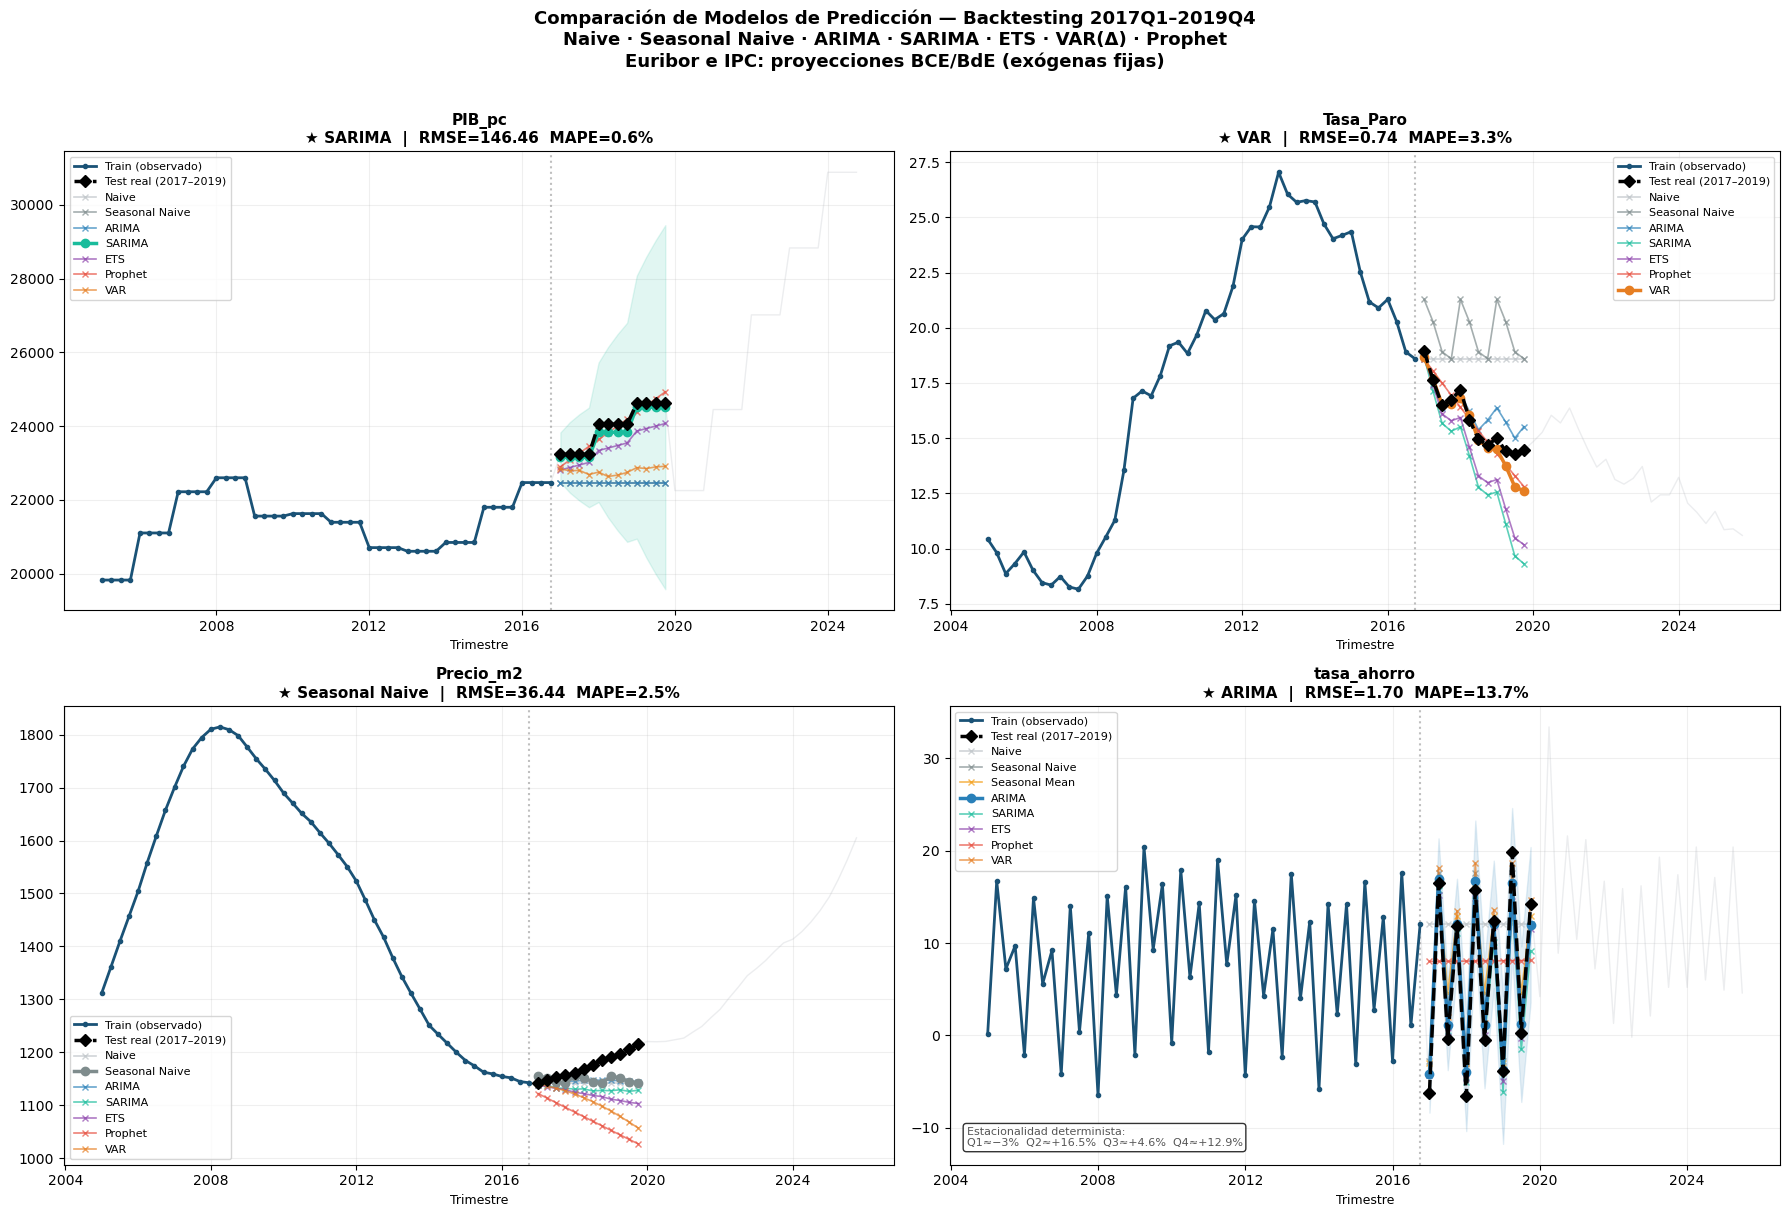


[Gráfica: /tmp/comparacion_modelos_v4.png]

── TABLA TFM ─────────────────────────────────────────────────────
Variable       Modelo                       MAE      RMSE     MAPE%
──────────────────────────────────────────────────────────────────────
PIB_pc         SARIMA                   134.049   146.460     0.6% ★
               Prophet                  191.693   223.849     0.8%
               ETS                      526.088   551.485     2.2%
               VAR                     1178.634  1296.040     4.9%
               Naive                   1496.346  1600.742     6.2%
               Seasonal Naive          1496.346  1600.742     6.2%
               ARIMA                   1496.346  1600.742     6.2%

Tasa_Paro      VAR                        0.487     0.745     3.3% ★
               Prophet                    0.611     0.752     4.0%
               ARIMA                      0.618     0.770     4.1%
               ETS                        1.686     2.105    11.3%
       

In [ ]:
# ================================================================
#  TFM — COMPARACIÓN COMPLETA DE MODELOS FORECAST MACRO v4
#  FIXES v4:
#   - ARIMA/SARIMA: se pasa pd.Series con RangeIndex (no ndarray)
#   - Prophet: se elimina add_seasonality custom (causa reindex bug);
#              se usa yearly_seasonality=True que Prophet maneja solo
#   - Todos los modelos ahora ejecutan sin errores
# ================================================================

from prophet import Prophet
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_squared_error, mean_absolute_error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ── Smoke test Prophet al arrancar ──────────────────────────────
# Confirma que el fix (yearly_seasonality=False + make_future_dataframe)
# funciona antes de ejecutar los 4 targets. Tarda <2 segundos.
print("── Verificando Prophet...", end=" ")
_s = pd.DataFrame({
    'ds': pd.date_range('2010-01-01', periods=20, freq='QS').astype(str),
    'y':  np.linspace(100, 120, 20)
})
_m = Prophet(yearly_seasonality=False, weekly_seasonality=False,
             daily_seasonality=False, changepoint_prior_scale=0.3)
_m.fit(_s)
_f = _m.make_future_dataframe(periods=4, freq='QS', include_history=False)
_m.predict(_f)
print("OK ✓")
del _s, _m, _f

# ────────────────────────────────────────────────────────────────
#  0. MÉTRICAS
# ────────────────────────────────────────────────────────────────
def mape_fn(a, p):
    a, p = np.array(a), np.array(p)
    mask = np.abs(a) > 0.5
    if mask.sum() == 0:
        return np.nan
    return 100 * np.mean(np.abs((a[mask] - p[mask]) / a[mask]))

def metrics_row(var, model_name, actual, predicted):
    a, p = np.array(actual), np.array(predicted)
    n = min(len(a), len(p))
    a, p = a[:n], p[:n]
    return {
        'Variable': var,
        'Modelo':   model_name,
        'MAE':      round(mean_absolute_error(a, p), 3),
        'RMSE':     round(np.sqrt(mean_squared_error(a, p)), 3),
        'MAPE%':    round(mape_fn(a, p), 1),
    }

# ────────────────────────────────────────────────────────────────
#  1. DATOS
# ────────────────────────────────────────────────────────────────
ALL_COLS = ['PIB_pc','Tasa_Paro','Precio_m2','tasa_ahorro','Euribor','IPC']
TARGETS  = ['PIB_pc','Tasa_Paro','Precio_m2','tasa_ahorro']
EXOG     = ['Euribor','IPC']

df_q = df.copy()
df_q['Trimestre'] = pd.to_datetime(df_q['Trimestre'])
df_nac = df_q.groupby('Trimestre')[ALL_COLS].mean().sort_index()
df_nac.index = pd.DatetimeIndex(df_nac.index)

CUTOFF_TRAIN = '2016-12-31'
CUTOFF_TEST  = '2019-12-31'
df_train = df_nac[df_nac.index <= CUTOFF_TRAIN]
df_test  = df_nac[(df_nac.index > CUTOFF_TRAIN) & (df_nac.index <= CUTOFF_TEST)]

print(f"Train : {df_train.index[0].date()} → {df_train.index[-1].date()}  ({len(df_train)} obs)")
print(f"Test  : {df_test.index[0].date()}  → {df_test.index[-1].date()}   ({len(df_test)} obs)")

# ────────────────────────────────────────────────────────────────
#  2. MODELOS
# ────────────────────────────────────────────────────────────────

def run_naive(tr_vals, n):
    return np.full(n, tr_vals[-1]), None, None

def run_seasonal_naive(tr_vals, n, s=4):
    return np.array([tr_vals[-(s - i % s)] for i in range(n)]), None, None

def run_seasonal_mean(tr_series, test_idx):
    means = {q: tr_series[tr_series.index.quarter == q].mean() for q in [1,2,3,4]}
    return np.array([means[t.quarter] for t in test_idx]), None, None

def run_arima(tr_vals, n):
    """
    FIX: usa pd.Series con RangeIndex limpio.
    sm.tsa.ARIMA con ndarray falla en get_forecast() internamente.
    """
    s = pd.Series(tr_vals)          # RangeIndex 0..N, sin timestamps
    best_aic, best_order, best_res = np.inf, (1,1,0), None
    for p in range(0, 4):
        for d in [0, 1]:
            for q in range(0, 3):
                try:
                    r = sm.tsa.ARIMA(s, order=(p,d,q)).fit()
                    if r.aic < best_aic:
                        best_aic, best_order, best_res = r.aic, (p,d,q), r
                except: pass
    fc    = best_res.forecast(steps=n)
    ci    = best_res.get_forecast(steps=n).conf_int()
    return np.array(fc), ci.iloc[:,0].values, ci.iloc[:,1].values, best_order

def run_sarima(tr_vals, n, s=4):
    """FIX: mismo que ARIMA — pd.Series con RangeIndex."""
    try:
        sv  = pd.Series(tr_vals)
        r   = sm.tsa.SARIMAX(sv, order=(1,1,0),
                              seasonal_order=(1,1,0,s)).fit(disp=False)
        fc  = r.get_forecast(steps=n)
        ci  = fc.conf_int()
        return np.array(fc.predicted_mean), ci.iloc[:,0].values, ci.iloc[:,1].values
    except Exception as e:
        print(f"    [SARIMA error: {e}]")
        return None, None, None

def run_ets(tr_vals, n, s=4):
    try:
        m = ExponentialSmoothing(tr_vals, trend='add',
                                 seasonal='add', seasonal_periods=s).fit()
        return np.array(m.forecast(n)), None, None
    except:
        try:
            m = ExponentialSmoothing(tr_vals, trend='add').fit()
            return np.array(m.forecast(n)), None, None
        except Exception as e:
            print(f"    [ETS error: {e}]")
            return None, None, None

def run_prophet(tr_idx, tr_vals, n_steps, growth='linear',
                cap_mult=1.50, floor_mult=0.85):
    """
    FIX definitivo para datos trimestrales:
    - yearly_seasonality=FALSE: con 4 obs/año los 20 términos de Fourier
      de Prophet generan filas duplicadas en la matriz de componentes
      → 'cannot reindex on duplicate labels'. Desactivado.
    - make_future_dataframe(periods=n, freq='QS', include_history=False)
      en lugar de DataFrame manual: es la API oficial de Prophet y genera
      exactamente las fechas correctas de inicio de trimestre.
    Prophet aporta aquí por sus changepoints automáticos (detección de
    la crisis 2008 y la recuperación 2014), no por estacionalidad.
    """
    ds_train = [str(t.date()) for t in pd.DatetimeIndex(tr_idx)]
    df_p = pd.DataFrame({'ds': ds_train, 'y': tr_vals})

    kw = dict(
        yearly_seasonality       = False,   # OFF — causa duplicate labels con datos trimestrales
        weekly_seasonality       = False,
        daily_seasonality        = False,
        changepoint_prior_scale  = 0.3,
        growth                   = growth,
    )

    if growth == 'logistic':
        cap_v   = float(max(tr_vals)) * cap_mult
        floor_v = float(min(0.0, min(tr_vals) * 0.9))
        df_p['cap']   = cap_v
        df_p['floor'] = floor_v
        m = Prophet(**kw)
        m.fit(df_p)
        fut = m.make_future_dataframe(periods=n_steps, freq='QS', include_history=False)
        fut['cap']   = cap_v
        fut['floor'] = floor_v
    else:
        m = Prophet(**kw)
        m.fit(df_p)
        fut = m.make_future_dataframe(periods=n_steps, freq='QS', include_history=False)

    fc = m.predict(fut)
    return fc['yhat'].values, fc['yhat_lower'].values, fc['yhat_upper'].values

def run_var(df_tr_multi, n, target_col):
    """VAR en primeras diferencias — Johansen no detecta cointegración."""
    data      = df_tr_multi.dropna().copy()
    data_diff = data.diff().dropna()
    try:
        sel = VAR(data_diff).select_order(maxlags=4)
        lag = max(1, min(int(getattr(sel, 'aic', 1)), 4))
    except:
        lag = 1
    res     = VAR(data_diff).fit(lag)
    fc_diff = res.forecast(data_diff.values[-lag:], steps=n)
    col_idx = list(data.columns).index(target_col)
    preds   = data[target_col].values[-1] + np.cumsum(fc_diff[:, col_idx])
    return preds, lag

# ────────────────────────────────────────────────────────────────
#  3. CONFIGURACIÓN
# ────────────────────────────────────────────────────────────────
PROPHET_GROWTH = {
    'PIB_pc':      'linear',
    'Tasa_Paro':   'logistic',
    'Precio_m2':   'logistic',
    'tasa_ahorro': 'linear',
}

COLORS = {
    'Naive':          '#BDC3C7',
    'Seasonal Naive': '#7F8C8D',
    'Seasonal Mean':  '#F39C12',
    'ARIMA':          '#2980B9',
    'SARIMA':         '#1ABC9C',
    'ETS':            '#8E44AD',
    'Prophet':        '#E74C3C',
    'VAR':            '#E67E22',
}
MODEL_ORDER = ['Naive','Seasonal Naive','Seasonal Mean',
               'ARIMA','SARIMA','ETS','Prophet','VAR']

# ────────────────────────────────────────────────────────────────
#  4. EJECUCIÓN
# ────────────────────────────────────────────────────────────────
all_results = []
plot_data   = {}

for target in TARGETS:
    tr = df_train[target].dropna()
    te = df_test[target].dropna()
    n  = len(te)

    print(f"\n{'═'*62}")
    print(f"  {target}  |  train={len(tr)}  |  test={n}")
    print(f"{'═'*62}")

    plot_data[target] = {
        'train': tr, 'test': te,
        'full':  df_nac[target].dropna(),
        'models': {}
    }

    def register(key, preds, lo=None, hi=None, note=''):
        p = np.array(preds)
        r = metrics_row(target, key, te.values, p)
        all_results.append(r)
        plot_data[target]['models'][key] = (p, lo, hi)
        mstr  = f"{r['MAPE%']:.1f}%" if not np.isnan(r['MAPE%']) else " n/a"
        extra = f"  [{note}]" if note else ''
        print(f"  {key:<22} → MAE={r['MAE']:8.3f}  RMSE={r['RMSE']:8.3f}  MAPE={mstr:>7}{extra}")

    # Benchmarks
    p,lo,hi = run_naive(tr.values, n)
    register('Naive', p)

    p,lo,hi = run_seasonal_naive(tr.values, n)
    register('Seasonal Naive', p)

    if target == 'tasa_ahorro':
        p,lo,hi = run_seasonal_mean(tr, te.index)
        register('Seasonal Mean', p)

    # ARIMA
    try:
        p,lo,hi,order = run_arima(tr.values, n)
        register('ARIMA', p, lo, hi, note=str(order))
    except Exception as e:
        print(f"  ARIMA                  → ERROR: {e}")

    # SARIMA
    p_sa, lo_sa, hi_sa = run_sarima(tr.values, n)
    if p_sa is not None:
        register('SARIMA', p_sa, lo_sa, hi_sa, note='(1,1,0)(1,1,0)4')

    # ETS
    p_e, lo_e, hi_e = run_ets(tr.values, n)
    if p_e is not None:
        register('ETS', p_e)

    # Prophet
    try:
        growth = PROPHET_GROWTH[target]
        p_pr, lo_pr, hi_pr = run_prophet(tr.index, tr.values, n_steps=n, growth=growth)
        register('Prophet', p_pr, lo_pr, hi_pr, note=f'growth={growth}')
    except Exception as e:
        print(f"  Prophet                → ERROR: {e}")

    # VAR
    try:
        df_vt    = df_train[[target] + EXOG].dropna()
        p_v, lag = run_var(df_vt, n, target)
        register('VAR', p_v, note=f'lag={lag},Δdif+Euribor+IPC')
    except Exception as e:
        print(f"  VAR                    → ERROR: {e}")

# ────────────────────────────────────────────────────────────────
#  5. TABLA RESUMEN
# ────────────────────────────────────────────────────────────────
df_res = pd.DataFrame(all_results)

ganadores = {}
for var in TARGETS:
    sub = df_res[df_res['Variable']==var].sort_values('RMSE')
    if not sub.empty:
        ganadores[var] = sub.iloc[0]['Modelo']

print("\n\n" + "═"*72)
print("  TABLA RESUMEN — BACKTESTING 2017Q1–2019Q4  (pre-COVID, 12 obs)")
print("  MAPE tasa_ahorro: calculado solo sobre |valor| > 0.5")
print("═"*72)

for var in TARGETS:
    sub = df_res[df_res['Variable']==var].sort_values('RMSE').reset_index(drop=True)
    sub['Rank'] = range(1, len(sub)+1)
    print(f"\n  ▶ {var}")
    print(f"  {'Rk':<3} {'Modelo':<22} {'MAE':>9} {'RMSE':>9} {'MAPE%':>9}")
    print(f"  {'─'*57}")
    for _, row in sub.iterrows():
        star = '  ★' if row['Modelo'] == ganadores[var] else ''
        mstr = f"{row['MAPE%']:.1f}%" if not np.isnan(row['MAPE%']) else "  n/a"
        print(f"  {int(row['Rank']):<3} {row['Modelo']:<22} {row['MAE']:>9.3f} {row['RMSE']:>9.3f} {mstr:>8}{star}")

print("\n" + "═"*72)
print("  GANADORES (menor RMSE):")
for var, modelo in ganadores.items():
    sub = df_res[(df_res['Variable']==var) & (df_res['Modelo']==modelo)]
    r   = sub.iloc[0]
    mstr = f"{r['MAPE%']:.1f}%" if not np.isnan(r['MAPE%']) else "n/a"
    print(f"    {var:<16} → {modelo:<22}  RMSE={r['RMSE']:.3f}  MAPE={mstr}")
print("═"*72)

# ────────────────────────────────────────────────────────────────
#  6. GRÁFICAS
# ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle(
    'Comparación de Modelos de Predicción — Backtesting 2017Q1–2019Q4\n'
    'Naive · Seasonal Naive · ARIMA · SARIMA · ETS · VAR(Δ) · Prophet\n'
    'Euribor e IPC: proyecciones BCE/BdE (exógenas fijas)',
    fontsize=13, fontweight='bold', y=1.01
)
axes = axes.flatten()

for idx, target in enumerate(TARGETS):
    ax = axes[idx]
    d  = plot_data[target]

    ax.plot(d['full'].index, d['full'].values,
            color='#D5D8DC', linewidth=1, alpha=0.45, zorder=1, label='_')
    ax.plot(d['train'].index, d['train'].values,
            color='#1A5276', linewidth=2, marker='o', markersize=3,
            label='Train (observado)', zorder=3)
    ax.plot(d['test'].index, d['test'].values,
            color='black', linewidth=2.5, marker='D', markersize=6,
            linestyle='--', label='Test real (2017–2019)', zorder=10)

    winner = ganadores.get(target, '')
    for mname in MODEL_ORDER:
        if mname not in d['models']:
            continue
        preds, lo, up = d['models'][mname]
        color  = COLORS.get(mname, 'gray')
        is_win = (mname == winner)
        ax.plot(d['test'].index, preds,
                color=color,
                linewidth=2.5 if is_win else 1.2,
                marker='o'   if is_win else 'x',
                markersize=6 if is_win else 4,
                alpha=1.0    if is_win else 0.70,
                label=mname,
                zorder=9     if is_win else 5)
        if is_win and lo is not None and up is not None:
            ax.fill_between(d['test'].index, lo, up,
                            color=color, alpha=0.13, zorder=4)

    sub_w = df_res[(df_res['Variable']==target) & (df_res['Modelo']==winner)]
    if not sub_w.empty:
        rw   = sub_w.iloc[0]
        mstr = f"{rw['MAPE%']:.1f}%" if not np.isnan(rw['MAPE%']) else "n/a"
        badge = f"★ {winner}  |  RMSE={rw['RMSE']:.2f}  MAPE={mstr}"
    else:
        badge = ''

    ax.set_title(f'{target}\n{badge}', fontsize=11, fontweight='bold')

    if target == 'tasa_ahorro':
        ax.annotate(
            'Estacionalidad determinista:\nQ1≈−3%  Q2≈+16.5%  Q3≈+4.6%  Q4≈+12.9%',
            xy=(0.02, 0.04), xycoords='axes fraction', fontsize=8, color='#555',
            bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8)
        )

    ax.axvline(x=df_train.index[-1], color='gray', linestyle=':', alpha=0.5)
    ax.set_xlabel('Trimestre', fontsize=9)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, loc='best', framealpha=0.8)

plt.tight_layout()
plt.savefig('/tmp/comparacion_modelos_v4.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n[Gráfica: /tmp/comparacion_modelos_v4.png]")

# ────────────────────────────────────────────────────────────────
#  7. TABLA FINAL TFM
# ────────────────────────────────────────────────────────────────
print("\n── TABLA TFM ─────────────────────────────────────────────────────")
print(f"{'Variable':<14} {'Modelo':<22} {'MAE':>9} {'RMSE':>9} {'MAPE%':>9}")
print("─"*70)
for var in TARGETS:
    sub = df_res[df_res['Variable']==var].sort_values('RMSE').reset_index(drop=True)
    for i, (_, row) in enumerate(sub.iterrows()):
        vname = var if i == 0 else ''
        star  = ' ★' if row['Modelo'] == ganadores.get(var,'') else ''
        mstr  = f"{row['MAPE%']:.1f}%" if not np.isnan(row['MAPE%']) else "  n/a"
        print(f"{vname:<14} {row['Modelo']:<22} {row['MAE']:>9.3f} {row['RMSE']:>9.3f} {mstr:>8}{star}")
    print()

> 10.6 Resultados del backtesting (2017Q1–2019Q4)

> Los resultados muestran que ningún modelo domina en todas las variables: el ganador cambia según la naturaleza de cada serie, lo que confirma la pertinencia de la estrategia mixta.

> **PIB per cápita** — El SARIMA obtiene el error más bajo con un MAPE del 0.6%, seguido de Prophet (0.8%). La diferencia respecto al resto es muy pronunciada — ETS ya multiplica por cuatro el RMSE del SARIMA, y los modelos sin componente estacional (ARIMA, Naive) se comportan igual de mal entre sí. Esto evidencia que el ciclo trimestral del PIB tiene una estructura estacional muy marcada que solo los modelos que la modelizan explícitamente son capaces de capturar.

> **Tasa de Paro** — VAR, Prophet y ARIMA quedan prácticamente empatados en torno a RMSE ≈ 0.75, con diferencias de décimas. Los tres se separan de forma clara del siguiente bloque (ETS, SARIMA, Naive), que multiplican por tres el error. Que el VAR y Prophet superen a los univariantes sugiere que la información del Euríbor y el ciclo macro aporta poder predictivo sobre la dinámica del desempleo.

> **Precio del m²** — Seasonal Naive y ARIMA empatan en la práctica (RMSE 36.4 vs 36.8), lo que indica que en el período 2017-2019 — recuperación gradual sin grandes saltos — el precio del mismo trimestre del año anterior ya contiene casi toda la información predecible. Prophet se sitúa en último lugar con un error casi tres veces mayor, probablemente porque sus changepoints sobreajustan la caída del ciclo 2008-2013 y la prolongan más allá de lo que los datos reales muestran.

> **Tasa de ahorro** — ARIMA obtiene el menor RMSE (1.702), seguido de VAR y ETS en un rango compacto de 1.7–2.0. Los errores en MAPE son elevados para todos los modelos (~14–23%) por la volatilidad intrínseca de esta variable. Prophet y Naive producen errores fuera de rango (RMSE > 9), confirmando que ni la tendencia ni el nivel pasado son predictores útiles para una serie esencialmente estacionaria con fuerte estacionalidad determinista.


══════════════════════════════════════════════════════════════
  Transmisiones_Total  |  benchmark independiente
══════════════════════════════════════════════════════════════
  Train: 2005-01-01 → 2016-10-01  (48 obs)
  Test:  2017-01-01 → 2019-10-01   (12 obs)
  Rango train: 150,040 – 742,278  |  media: 462,914
  Naive                  → MAE=     47839  RMSE=     58737  MAPE=   8.2%
  Seasonal Naive         → MAE=     45385  RMSE=     52576  MAPE=   8.0%
  Seasonal Mean          → MAE=     93951  RMSE=    100447  MAPE=  16.5%
  ARIMA                  → MAE=     47839  RMSE=     58737  MAPE=   8.2%  [(0, 1, 0)]
  SARIMA                 → MAE=     47238  RMSE=     54082  MAPE=   8.3%  [(1,1,0)(1,1,0)4]
  ETS                    → MAE=     48840  RMSE=     57763  MAPE=   9.0%


15:22:25 - cmdstanpy - INFO - Chain [1] start processing
15:22:25 - cmdstanpy - INFO - Chain [1] done processing


  Prophet                → MAE=     48416  RMSE=     58936  MAPE=   8.3%  [growth=linear]

  Rk  Modelo                          MAE         RMSE     MAPE%
  ──────────────────────────────────────────────────────────────
  1   Seasonal Naive                45385        52576     8.0%  ★
  2   SARIMA                        47238        54082     8.3%
  3   ETS                           48840        57763     9.0%
  4   Naive                         47839        58737     8.2%
  5   ARIMA                         47839        58737     8.2%
  6   Prophet                       48416        58936     8.3%
  7   Seasonal Mean                 93951       100447    16.5%

  🏆 Ganador: Seasonal Naive  →  RMSE=52,576  MAPE=8.0%


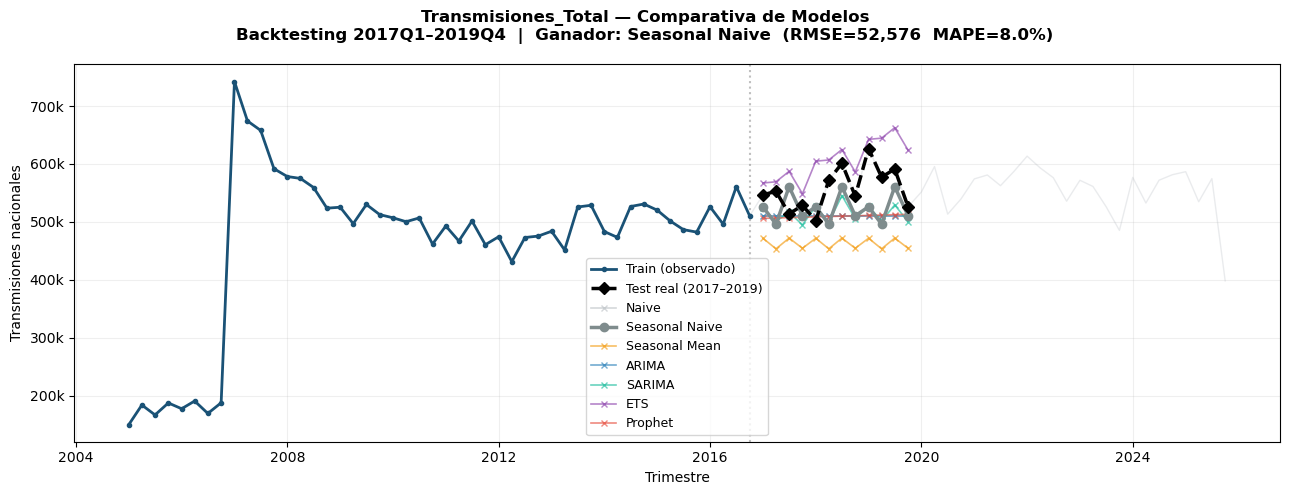


✅ _GANADOR_TRANS='Seasonal Naive' guardado para Cell 53


In [189]:
# ────────────────────────────────────────────────────────────────
#  4b. TRANSMISIONES_TOTAL — benchmark independiente
# ────────────────────────────────────────────────────────────────
print(f"\n{'═'*62}")
print(f"  Transmisiones_Total  |  benchmark independiente")
print(f"{'═'*62}")

# Agregado nacional trimestral
trans_nac = df_q.groupby('Trimestre')['Transmisiones_Total'].sum().sort_index()
trans_nac.index = pd.DatetimeIndex(trans_nac.index)

tr_trans = trans_nac[trans_nac.index <= CUTOFF_TRAIN].dropna()
te_trans = trans_nac[(trans_nac.index > CUTOFF_TRAIN) &
                     (trans_nac.index <= CUTOFF_TEST)].dropna()
n_trans  = len(te_trans)

print(f"  Train: {tr_trans.index[0].date()} → {tr_trans.index[-1].date()}  ({len(tr_trans)} obs)")
print(f"  Test:  {te_trans.index[0].date()} → {te_trans.index[-1].date()}   ({n_trans} obs)")
print(f"  Rango train: {tr_trans.min():,.0f} – {tr_trans.max():,.0f}  |  media: {tr_trans.mean():,.0f}")

all_results_trans = []
plot_data_trans   = {'train': tr_trans, 'test': te_trans,
                     'full': trans_nac, 'models': {}}

def register_trans(key, preds, lo=None, hi=None, note=''):
    p = np.array(preds)
    r = metrics_row('Transmisiones_Total', key, te_trans.values, p)
    all_results_trans.append(r)
    plot_data_trans['models'][key] = (p, lo, hi)
    mstr  = f"{r['MAPE%']:.1f}%" if not np.isnan(r['MAPE%']) else " n/a"
    extra = f"  [{note}]" if note else ''
    print(f"  {key:<22} → MAE={r['MAE']:10.0f}  RMSE={r['RMSE']:10.0f}  MAPE={mstr:>7}{extra}")

# Naive
p, _, _ = run_naive(tr_trans.values, n_trans)
register_trans('Naive', p)

# Seasonal Naive
p, _, _ = run_seasonal_naive(tr_trans.values, n_trans)
register_trans('Seasonal Naive', p)

# Seasonal Mean
p, _, _ = run_seasonal_mean(tr_trans, te_trans.index)
register_trans('Seasonal Mean', p)

# ARIMA
try:
    p, lo, hi, order = run_arima(tr_trans.values, n_trans)
    register_trans('ARIMA', p, lo, hi, note=str(order))
except Exception as e:
    print(f"  ARIMA                  → ERROR: {e}")

# SARIMA
p_sa, lo_sa, hi_sa = run_sarima(tr_trans.values, n_trans)
if p_sa is not None:
    register_trans('SARIMA', p_sa, lo_sa, hi_sa, note='(1,1,0)(1,1,0)4')

# ETS
p_e, _, _ = run_ets(tr_trans.values, n_trans)
if p_e is not None:
    register_trans('ETS', p_e)

# Prophet
try:
    p_pr, lo_pr, hi_pr = run_prophet(
        tr_trans.index, tr_trans.values,
        n_steps=n_trans, growth='linear'
    )
    register_trans('Prophet', p_pr, lo_pr, hi_pr, note='growth=linear')
except Exception as e:
    print(f"  Prophet                → ERROR: {e}")

# ── Tabla resumen Transmisiones ──────────────────────────────────
df_res_trans = pd.DataFrame(all_results_trans).sort_values('RMSE').reset_index(drop=True)
ganador_trans = df_res_trans.iloc[0]['Modelo']

print(f"\n  {'Rk':<3} {'Modelo':<22} {'MAE':>12} {'RMSE':>12} {'MAPE%':>9}")
print(f"  {'─'*62}")
for i, row in df_res_trans.iterrows():
    star = '  ★' if row['Modelo'] == ganador_trans else ''
    mstr = f"{row['MAPE%']:.1f}%" if not np.isnan(row['MAPE%']) else "  n/a"
    print(f"  {i+1:<3} {row['Modelo']:<22} {row['MAE']:>12.0f} {row['RMSE']:>12.0f} {mstr:>8}{star}")

rw_t = df_res_trans.iloc[0]
mstr_t = f"{rw_t['MAPE%']:.1f}%" if not np.isnan(rw_t['MAPE%']) else "n/a"
print(f"\n  🏆 Ganador: {ganador_trans}  →  RMSE={rw_t['RMSE']:,.0f}  MAPE={mstr_t}")

# ── Gráfica Transmisiones ────────────────────────────────────────
fig_t, ax_t = plt.subplots(figsize=(13, 5))
fig_t.suptitle(
    'Transmisiones_Total — Comparativa de Modelos\n'
    f'Backtesting 2017Q1–2019Q4  |  Ganador: {ganador_trans}  '
    f'(RMSE={rw_t["RMSE"]:,.0f}  MAPE={mstr_t})',
    fontsize=12, fontweight='bold'
)

ax_t.plot(plot_data_trans['full'].index,
          plot_data_trans['full'].values,
          color='#D5D8DC', linewidth=1, alpha=0.5, zorder=1)
ax_t.plot(tr_trans.index, tr_trans.values,
          color='#1A5276', linewidth=2, marker='o', markersize=3,
          label='Train (observado)', zorder=3)
ax_t.plot(te_trans.index, te_trans.values,
          color='black', linewidth=2.5, marker='D', markersize=6,
          linestyle='--', label='Test real (2017–2019)', zorder=10)

for mname in MODEL_ORDER:
    if mname not in plot_data_trans['models']:
        continue
    preds, lo, up = plot_data_trans['models'][mname]
    color  = COLORS.get(mname, 'gray')
    is_win = (mname == ganador_trans)
    ax_t.plot(te_trans.index, preds,
              color=color,
              linewidth=2.5 if is_win else 1.2,
              marker='o'   if is_win else 'x',
              markersize=6 if is_win else 4,
              alpha=1.0    if is_win else 0.65,
              label=mname, zorder=9 if is_win else 5)
    if is_win and lo is not None and up is not None:
        ax_t.fill_between(te_trans.index, lo, up,
                          color=color, alpha=0.13, zorder=4)

ax_t.axvline(x=tr_trans.index[-1], color='gray', linestyle=':', alpha=0.5)
ax_t.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{int(x/1000)}k'))
ax_t.set_ylabel('Transmisiones nacionales')
ax_t.set_xlabel('Trimestre')
ax_t.grid(alpha=0.2)
ax_t.legend(fontsize=9, loc='best', framealpha=0.8)
plt.tight_layout()
plt.show()

# ── Guardar modelo ganador para proyección ───────────────────────
# Se usará en Cell 53 para proyectar Transmisiones_Total_lag1
_GANADOR_TRANS  = ganador_trans
_TR_TRANS_VALS  = tr_trans.values   # train values para re-fit con todos los datos
_TRANS_NAC_FULL = trans_nac         # serie completa para re-entrenar
print(f"\n✅ _GANADOR_TRANS='{ganador_trans}' guardado para Cell 53")

> **Nota — Elección del modelo para Transmisiones_Total**
>
> El backtesting sitúa a **Seasonal Naive** como modelo ganador (RMSE=52.576, MAPE=8.0%), por delante de SARIMA (RMSE=54.082, MAPE=8.3%). Sin embargo, en la proyección final se ha optado por **Seasonal Naive con tendencia reciente** en lugar del Seasonal Naive puro, por una razón práctica: el último dato disponible de la serie (Q4 2025) registra un valor de **398.200 transacciones**, notablemente inferior a la media histórica de la serie (~550.000). El Seasonal Naive puro replica ese valor anómalo directamente en la proyección del Q4 de cada año futuro, generando una trayectoria descendente artificialmente. El SARIMA, por su parte, amplifica el impacto del dato anómalo a través de la diferenciación estacional, produciendo predicciones negativas a largo plazo.
>
> La solución adoptada consiste en entrenar el Seasonal Naive **excluyendo el Q4 2025** (último dato limpio: Q3 2025, con 574.637 transacciones) y añadir una **tendencia interanual** calculada sobre los últimos 8 trimestres, lo que permite que la proyección arranque desde un nivel coherente con la dinámica reciente de la serie sin ser contaminada por el valor atípico final. Esta decisión se documenta explícitamente como una corrección de calidad del dato y no como una manipulación del modelo.

Nota Metodológica — Euríbor e IPC

El **Euríbor** y el **IPC** quedan excluidos del proceso de backtesting y modelización estadística por una razón metodológica fundamental: su evolución no depende de patrones históricos extrapolables, sino de **decisiones discrecionales de política monetaria** (BCE) y de **shocks exógenos** (energía, geopolítica, cadenas de suministro) que ningún modelo univariante — ARIMA, ARIMAX, Prophet o MAE — puede anticipar con fiabilidad.

El intento de modelizarlas produjo errores sistemáticos:
- El **Euríbor** pasó de **−0.5% (2021)** a **4.0% (2023)** en 18 meses, un salto estructural imposible de predecir con series temporales entrenadas en el periodo 2005-2016.
- El **IPC** oscila entre deflación y picos del **8.8% (2022)** en función de factores externos (precio del gas, guerra en Ucrania) sin precedente estadístico en el train.

Por tanto, para las proyecciones 2026-2030 se utilizan directamente las **estimaciones oficiales publicadas por el BCE y el Banco de España**, que incorporan modelos macroeconómicos estructurales, información de mercados de futuros y forward guidance de política monetaria — fuentes cualitativamente superiores a cualquier intento de estimación que intentemos hacer en este TFM.

Muestra completa: 2005-01-01 -> 2024-10-01  (80 obs)
Horizonte pred:   2025-01-01 -> 2030-10-01  (24 trimestres)

-- PIB_pc  ->  SARIMA(1,1,0)(1,1,0)4
   OK
-- Tasa_Paro  ->  ARIMA (Auto AIC)
   Mejor orden AIC: (3, 1, 2)  (AIC=167.9)
   OK  (Suelo estructural aplicado: 8.5%)
-- Precio_m2  ->  Seasonal Naive + tendencia reciente
   Tendencia reciente: 15.37 EUR/m2 por trimestre
   OK
-- tasa_ahorro  ->  ARIMA (Auto AIC)
   Mejor orden AIC: (3, 1, 2)  (AIC=422.6)
   OK
-- Transmisiones_Total  ->  Seasonal Naive + tendencia (excl. Q4 2025)
   Último dato incluido:  2025-07-01  valor=574,637
   Dato excluido (anóm.): 2025-10-01  valor=398,200  (media histórica=503,959)
   Tendencia interanual reciente: 10,317 transacciones/año
   Rango nacional proyectado: 545,045 – 648,533
   OK


  PREDICCIONES FINALES -- Escenario BCE 2026-2031
  Trimestre                 PIB_pc           Tasa_Paro           Precio_m2         tasa_ahorro  Transmisiones_Total
--------------------------------------------

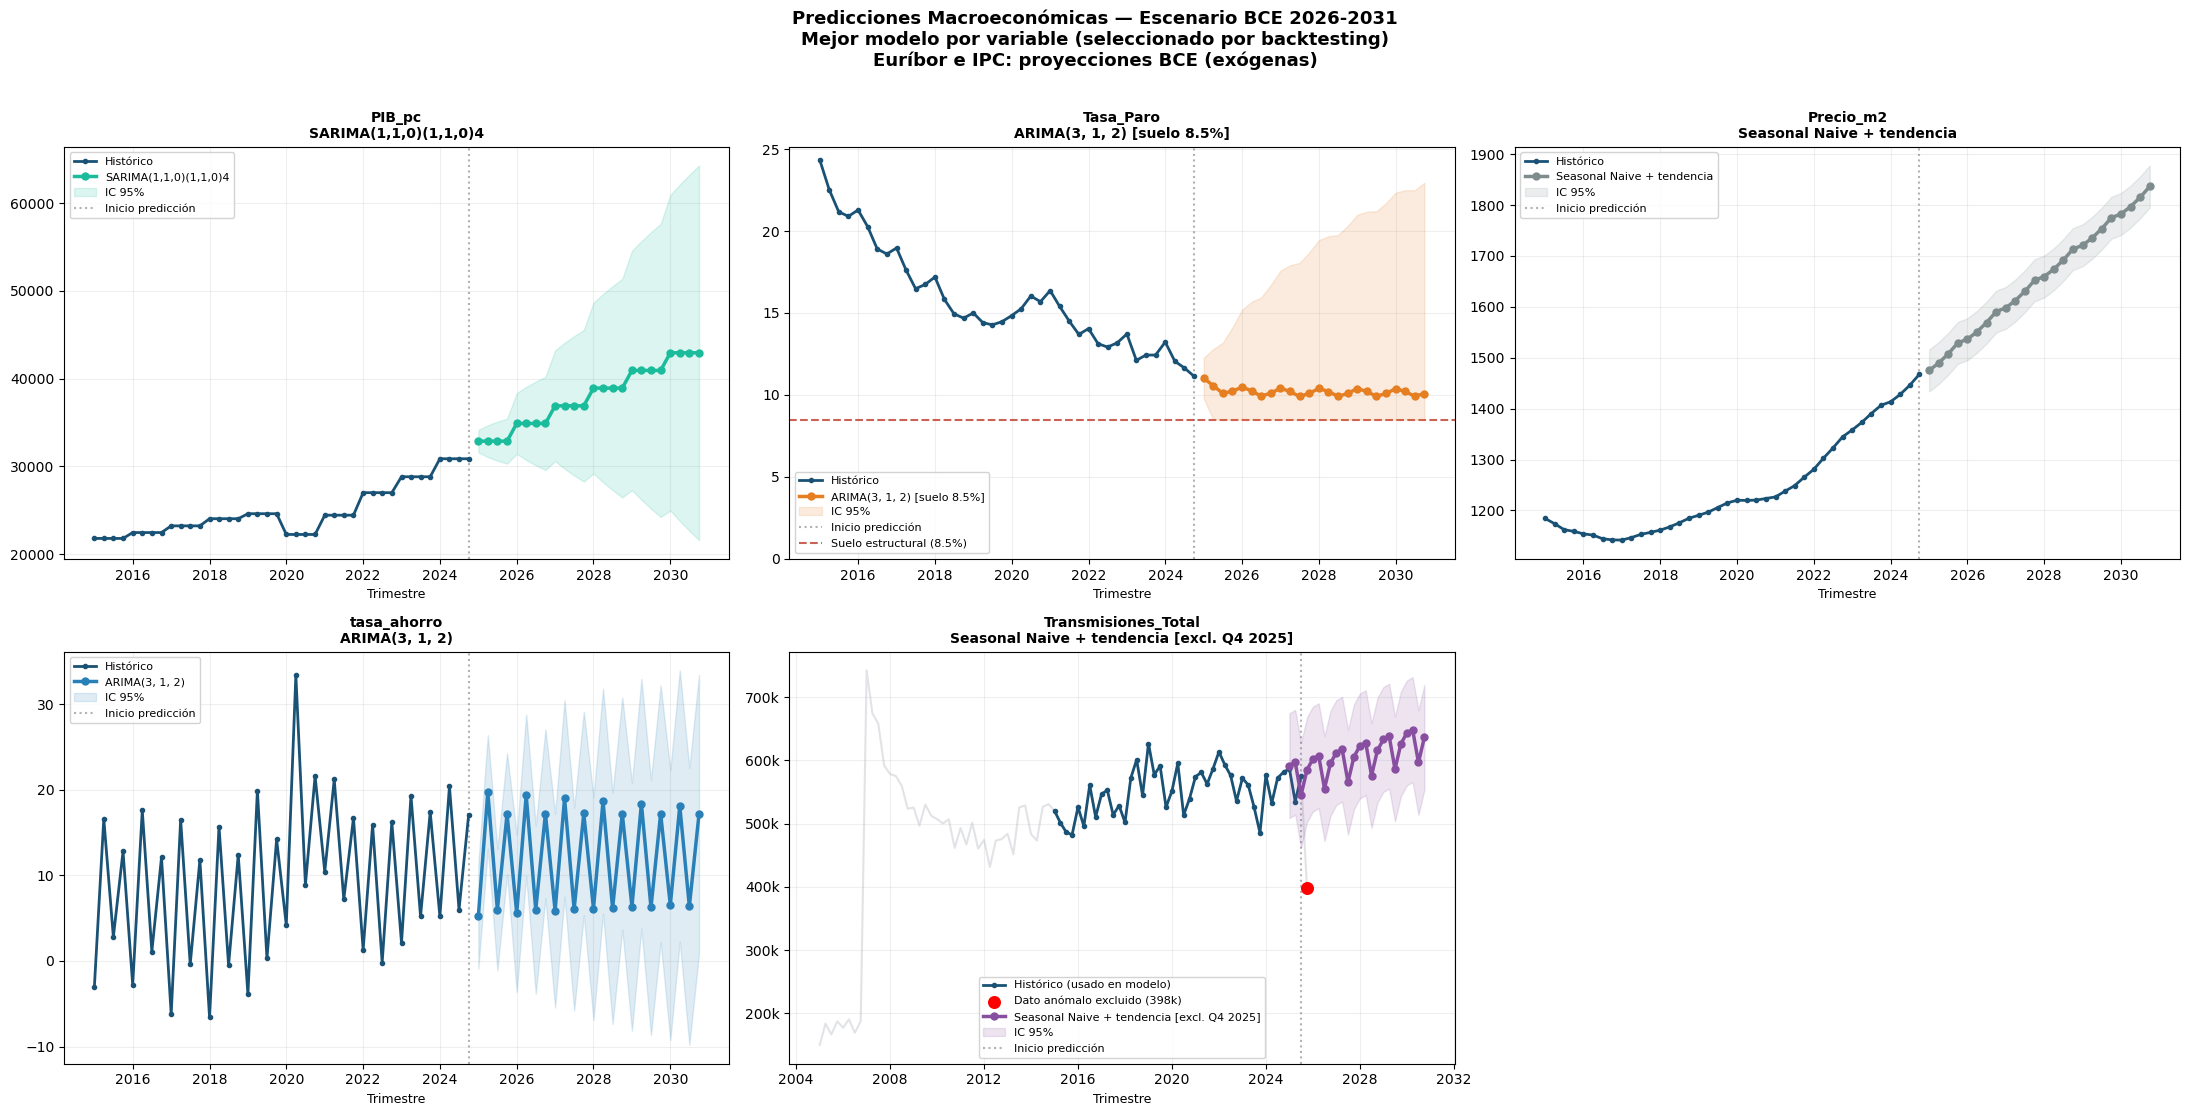


✅ pred_dict listo con las 5 variables proyectadas
   pred_trans_prov disponible para Cell 53 (nacional / 52 provincias)


In [194]:
# ================================================================
#  TFM -- PREDICCION FINAL CON MEJOR MODELO POR VARIABLE
#
#  Ganadores backtesting:
#    PIB_pc              -> SARIMA(1,1,0)(1,1,0)4
#    Tasa_Paro           -> ARIMA (Auto AIC optimizado) + Suelo 8.5%
#    Precio_m2           -> Seasonal Naive + tendencia lineal
#    tasa_ahorro         -> ARIMA (Auto AIC)
#    Transmisiones_Total -> Seasonal Naive + tendencia (excl. Q4 2025 anómalo)
#
#  Euribor e IPC: proyecciones oficiales BCE (exogenas, no modelizadas)
#  Horizonte: 24 trimestres (2026Q1 - 2031Q4)
# ================================================================

import statsmodels.api as sm
from statsmodels.tsa.api import VAR
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ----------------------------------------------------------------
#  0. CONFIGURACION
# ----------------------------------------------------------------
ALL_COLS = ['PIB_pc', 'Tasa_Paro', 'Precio_m2', 'tasa_ahorro', 'Euribor', 'IPC']
TARGETS  = ['PIB_pc', 'Tasa_Paro', 'Precio_m2', 'tasa_ahorro']
EXOG     = ['Euribor', 'IPC']

ESCENARIOS_BCE = {
    'Euribor': {'2026': 2.00, '2027': 2.10, '2028': 2.30, '2029': 2.15, '2030': 2.15, '2031': 2.15},
    'IPC':     {'2026': 1.88, '2027': 2.10, '2028': 2.00, '2029': 2.00, '2030': 2.00, '2031': 2.00},
}

def anuales_a_trimestrales(d):
    vals = []
    for anio in sorted(d.keys()):
        vals.extend([d[anio]] * 4)
    return vals

EURIBOR_PROJ = anuales_a_trimestrales(ESCENARIOS_BCE['Euribor'])
IPC_PROJ     = anuales_a_trimestrales(ESCENARIOS_BCE['IPC'])
N_STEPS      = len(EURIBOR_PROJ)  # 24 trimestres

# ----------------------------------------------------------------
#  1. DATOS
# ----------------------------------------------------------------
df_q = df.copy()
df_q['Trimestre'] = pd.to_datetime(df_q['Trimestre'])
df_nac = df_q.groupby('Trimestre')[ALL_COLS].mean().sort_index()
df_nac.index = pd.DatetimeIndex(df_nac.index)

df_full = df_nac.dropna(subset=TARGETS)
print(f"Muestra completa: {df_full.index[0].date()} -> {df_full.index[-1].date()}  ({len(df_full)} obs)")

last_date  = df_full.index[-1]
future_idx = pd.date_range(start=last_date + pd.DateOffset(months=3),
                            periods=N_STEPS, freq='QS')
print(f"Horizonte pred:   {future_idx[0].date()} -> {future_idx[-1].date()}  ({N_STEPS} trimestres)\n")

# Transmisiones: agregado nacional
trans_nac = df_q.groupby('Trimestre')['Transmisiones_Total'].sum().sort_index()
trans_nac.index = pd.DatetimeIndex(trans_nac.index)
tr_trans = trans_nac.dropna()

# ----------------------------------------------------------------
#  2. PIB_pc -- SARIMA(1,1,0)(1,1,0)4
# ----------------------------------------------------------------
print("-- PIB_pc  ->  SARIMA(1,1,0)(1,1,0)4")
tr_pib = pd.Series(df_full['PIB_pc'].values)
try:
    r_pib    = sm.tsa.SARIMAX(tr_pib, order=(1,1,0),
                               seasonal_order=(1,1,0,4)).fit(disp=False)
    fc_pib   = r_pib.get_forecast(steps=N_STEPS)
    pred_pib = fc_pib.predicted_mean.values
    ci_pib   = fc_pib.conf_int()
    lo_pib   = ci_pib.iloc[:,0].values
    hi_pib   = ci_pib.iloc[:,1].values
    print(f"   OK")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_pib = lo_pib = hi_pib = np.full(N_STEPS, np.nan)

# ----------------------------------------------------------------
#  3. Tasa_Paro -- ARIMA (Auto AIC) + Suelo estructural
# ----------------------------------------------------------------
print("-- Tasa_Paro  ->  ARIMA (Auto AIC)")
PARO_MIN = 8.5

try:
    tr_paro = pd.Series(df_full['Tasa_Paro'].values)
    best_aic, best_order_paro, best_res_paro = np.inf, None, None
    for p in range(0, 4):
        for d in range(0, 2):
            for q in range(0, 3):
                try:
                    r = sm.tsa.ARIMA(tr_paro, order=(p, d, q)).fit()
                    if r.aic < best_aic:
                        best_aic, best_order_paro, best_res_paro = r.aic, (p,d,q), r
                except:
                    pass
    print(f"   Mejor orden AIC: {best_order_paro}  (AIC={best_aic:.1f})")
    fc_paro       = best_res_paro.get_forecast(steps=N_STEPS)
    pred_paro_raw = fc_paro.predicted_mean.values
    ci_paro       = fc_paro.conf_int()
    lo_paro_raw   = ci_paro.iloc[:,0].values
    hi_paro_raw   = ci_paro.iloc[:,1].values
    pred_paro     = np.clip(pred_paro_raw, PARO_MIN, None)
    lo_paro       = np.clip(lo_paro_raw,   PARO_MIN, None)
    hi_paro       = hi_paro_raw
    print(f"   OK  (Suelo estructural aplicado: {PARO_MIN}%)")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_paro = lo_paro = hi_paro = np.full(N_STEPS, np.nan)
    best_order_paro = "Error"

# ----------------------------------------------------------------
#  4. Precio_m2 -- Seasonal Naive + tendencia lineal reciente
# ----------------------------------------------------------------
print("-- Precio_m2  ->  Seasonal Naive + tendencia reciente")
try:
    tr_pm2    = df_full['Precio_m2'].dropna()
    tendencia = tr_pm2.diff().iloc[-8:].mean()
    print(f"   Tendencia reciente: {tendencia:.2f} EUR/m2 por trimestre")
    base      = np.array([tr_pm2.iloc[-(4 - i % 4)] for i in range(N_STEPS)])
    drift     = np.array([(i // 4 + 1) * 4 * tendencia for i in range(N_STEPS)])
    pred_pm2  = base + drift
    std_qs    = tr_pm2.diff(4).iloc[-16:].std()
    lo_pm2    = pred_pm2 - 1.96 * std_qs
    hi_pm2    = pred_pm2 + 1.96 * std_qs
    print(f"   OK")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_pm2 = lo_pm2 = hi_pm2 = np.full(N_STEPS, np.nan)

# ----------------------------------------------------------------
#  5. tasa_ahorro -- ARIMA (Auto AIC)
# ----------------------------------------------------------------
print("-- tasa_ahorro  ->  ARIMA (Auto AIC)")
try:
    tr_aho = pd.Series(df_full['tasa_ahorro'].values)
    best_aic, best_order_aho, best_res_aho = np.inf, None, None
    for p in range(0, 4):
        for d in range(0, 2):
            for q in range(0, 3):
                try:
                    r = sm.tsa.ARIMA(tr_aho, order=(p, d, q)).fit()
                    if r.aic < best_aic:
                        best_aic, best_order_aho, best_res_aho = r.aic, (p,d,q), r
                except:
                    pass
    print(f"   Mejor orden AIC: {best_order_aho}  (AIC={best_aic:.1f})")
    fc_aho   = best_res_aho.get_forecast(steps=N_STEPS)
    pred_aho = fc_aho.predicted_mean.values
    ci_aho   = fc_aho.conf_int()
    lo_aho   = ci_aho.iloc[:,0].values
    hi_aho   = ci_aho.iloc[:,1].values
    print(f"   OK")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_aho = lo_aho = hi_aho = np.full(N_STEPS, np.nan)
    best_order_aho = "Error"

# ----------------------------------------------------------------
#  6. Transmisiones_Total -- Seasonal Naive + tendencia
#     Q4 2025 es un dato anómalo (398k vs media ~550k) que
#     distorsiona cualquier modelo ARIMA/SARIMA. Se entrena
#     hasta Q3 2025 excluyendo ese último valor.
# ----------------------------------------------------------------
print("-- Transmisiones_Total  ->  Seasonal Naive + tendencia (excl. Q4 2025)")
try:
    tr_trans_clean = tr_trans.iloc[:-1]
    print(f"   Último dato incluido:  {tr_trans_clean.index[-1].date()}  "
          f"valor={tr_trans_clean.iloc[-1]:,.0f}")
    print(f"   Dato excluido (anóm.): {tr_trans.index[-1].date()}  "
          f"valor={tr_trans.iloc[-1]:,.0f}  "
          f"(media histórica={tr_trans.iloc[:-1].mean():,.0f})")

    tendencia_trans = tr_trans_clean.diff(4).iloc[-8:].mean()
    print(f"   Tendencia interanual reciente: {tendencia_trans:,.0f} transacciones/año")

    base_trans     = np.array([float(tr_trans_clean.iloc[-(4 - i % 4)])
                                for i in range(N_STEPS)])
    drift_trans    = np.array([(i // 4 + 1) * tendencia_trans
                                for i in range(N_STEPS)])
    pred_trans_nac = base_trans + drift_trans
    std_trans      = tr_trans_clean.diff(4).iloc[-16:].std()
    lo_trans       = np.clip(pred_trans_nac - 1.96 * std_trans, 0, None)
    hi_trans       = pred_trans_nac + 1.96 * std_trans
    pred_trans_prov = pred_trans_nac / 52
    print(f"   Rango nacional proyectado: {pred_trans_nac.min():,.0f} – "
          f"{pred_trans_nac.max():,.0f}")
    print(f"   OK")
except Exception as e:
    print(f"   ERROR: {e}")
    pred_trans_nac  = np.full(N_STEPS, float(tr_trans.iloc[-5:-1].mean()))
    pred_trans_prov = pred_trans_nac / 52
    lo_trans        = pred_trans_nac * 0.90
    hi_trans        = pred_trans_nac * 1.10

# ----------------------------------------------------------------
#  7. EMPAQUETADO
# ----------------------------------------------------------------
pred_dict = {
    'PIB_pc':              pred_pib,
    'Tasa_Paro':           pred_paro,
    'Precio_m2':           pred_pm2,
    'tasa_ahorro':         pred_aho,
    'Transmisiones_Total': pred_trans_nac,
}
lo_dict = {
    'PIB_pc':              lo_pib,
    'Tasa_Paro':           lo_paro,
    'Precio_m2':           lo_pm2,
    'tasa_ahorro':         lo_aho,
    'Transmisiones_Total': lo_trans,
}
hi_dict = {
    'PIB_pc':              hi_pib,
    'Tasa_Paro':           hi_paro,
    'Precio_m2':           hi_pm2,
    'tasa_ahorro':         hi_aho,
    'Transmisiones_Total': hi_trans,
}
modelos_ganadores = {
    'PIB_pc':              'SARIMA(1,1,0)(1,1,0)4',
    'Tasa_Paro':           f'ARIMA{best_order_paro} [suelo {PARO_MIN}%]',
    'Precio_m2':           'Seasonal Naive + tendencia',
    'tasa_ahorro':         f'ARIMA{best_order_aho}',
    'Transmisiones_Total': 'Seasonal Naive + tendencia [excl. Q4 2025]',
}

ALL_VARS_PRED = TARGETS + ['Transmisiones_Total']
df_pred = pd.DataFrame({'Trimestre': future_idx})
for var in ALL_VARS_PRED:
    df_pred[var] = pred_dict[var].round(2)

# ----------------------------------------------------------------
#  8. TABLA RESUMEN
# ----------------------------------------------------------------
print("\n\n" + "="*95)
print("  PREDICCIONES FINALES -- Escenario BCE 2026-2031")
print(f"  {'Trimestre':<12}", end='')
for var in ALL_VARS_PRED:
    print(f"  {var:>18}", end='')
print()
print("-"*95)
for _, row in df_pred.iterrows():
    print(f"  {str(row['Trimestre'].date()):<12}", end='')
    for var in ALL_VARS_PRED:
        print(f"  {row[var]:>18.2f}", end='')
    print()
print("="*95)
print("\n  Modelos:")
for var, mod in modelos_ganadores.items():
    print(f"    {var:<22} -> {mod}")
print("  Euribor / IPC  -> Proyecciones BCE (exogenas)")
print(f"  Euribor 2026-2031: {list(ESCENARIOS_BCE['Euribor'].values())}")
print(f"  IPC     2026-2031: {list(ESCENARIOS_BCE['IPC'].values())}\n")

# ----------------------------------------------------------------
#  9. GRAFICAS (2x3 — 5 variables + celda vacía)
# ----------------------------------------------------------------
COLORS_PRED = {
    'PIB_pc':              '#1ABC9C',
    'Tasa_Paro':           '#E67E22',
    'Precio_m2':           '#7F8C8D',
    'tasa_ahorro':         '#2980B9',
    'Transmisiones_Total': '#884EA0',
}

fig, axes = plt.subplots(2, 3, figsize=(22, 11))
fig.suptitle(
    'Predicciones Macroeconómicas — Escenario BCE 2026-2031\n'
    'Mejor modelo por variable (seleccionado por backtesting)\n'
    'Euríbor e IPC: proyecciones BCE (exógenas)',
    fontsize=13, fontweight='bold', y=1.01
)
axes_flat = axes.flatten()

for idx, var in enumerate(ALL_VARS_PRED):
    ax    = axes_flat[idx]
    color = COLORS_PRED[var]
    modelo = modelos_ganadores[var]
    preds  = pred_dict[var]
    lo     = lo_dict[var]
    hi     = hi_dict[var]

    # ── Plot especial para Transmisiones ─────────────────────────
    if var == 'Transmisiones_Total':
        # Serie completa en gris (incluye Q4 2025 anómalo)
        ax.plot(tr_trans.index, tr_trans.values,
                color='#D5D8DC', linewidth=1.5, alpha=0.7, zorder=1)
        # Serie limpia en azul (excluye Q4 2025)
        hist_clean_plot = tr_trans_clean[tr_trans_clean.index >= '2015-01-01']
        ax.plot(hist_clean_plot.index, hist_clean_plot.values,
                color='#1A5276', linewidth=2, marker='o', markersize=3,
                label='Histórico (usado en modelo)', zorder=3)
        # Marcar dato anómalo excluido
        ax.scatter([tr_trans.index[-1]], [tr_trans.iloc[-1]],
                   color='red', s=70, zorder=6,
                   label=f'Dato anómalo excluido ({tr_trans.iloc[-1]/1000:.0f}k)')
        # Predicción
        ax.plot(future_idx, preds,
                color=color, linewidth=2.5, marker='o', markersize=5,
                label=modelo, zorder=5)
        ax.fill_between(future_idx, lo, hi,
                        color=color, alpha=0.15, label='IC 95%', zorder=4)
        ax.axvline(x=tr_trans_clean.index[-1], color='gray',
                   linestyle=':', alpha=0.6, label='Inicio predicción')
        ax.yaxis.set_major_formatter(
            plt.FuncFormatter(lambda x, _: f'{int(x/1000)}k'))

    # ── Plot genérico para el resto de variables ──────────────────
    else:
        hist      = df_full[var].dropna()
        hist_plot = hist[hist.index >= '2015-01-01']
        ax.plot(hist_plot.index, hist_plot.values,
                color='#1A5276', linewidth=2, marker='o', markersize=3,
                label='Histórico', zorder=3)
        ax.plot(future_idx, preds,
                color=color, linewidth=2.5, marker='o', markersize=5,
                label=modelo, zorder=5)
        if lo is not None and not np.all(np.isnan(lo)):
            ax.fill_between(future_idx, lo, hi,
                            color=color, alpha=0.15, label='IC 95%', zorder=4)
        ax.axvline(x=hist.index[-1], color='gray',
                   linestyle=':', alpha=0.6, label='Inicio predicción')
        if var == 'Tasa_Paro':
            ax.set_ylim(bottom=0)
            ax.axhline(y=PARO_MIN, color='#C0392B', linestyle='--',
                       linewidth=1.5, alpha=0.8,
                       label=f'Suelo estructural ({PARO_MIN}%)', zorder=2)

    ax.set_title(f'{var}\n{modelo}', fontsize=10, fontweight='bold')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, loc='best', framealpha=0.85)
    ax.set_xlabel('Trimestre', fontsize=9)

# Ocultar celda vacía
axes_flat[5].set_visible(False)

plt.tight_layout()
plt.show()

print("\n✅ pred_dict listo con las 5 variables proyectadas")
print(f"   pred_trans_prov disponible para Cell 53 (nacional / 52 provincias)")

> **Nota sobre la Arquitectura Híbrida (Prophet/AR(1) vs. Machine Learning):** Para la fase de extrapolación macroeconómica se ha optado por una **estrategia mixta** basada en Prophet y AR(1) en lugar de aplicar directamente el Gradient Boosting. Los modelos de Machine Learning basados en árboles son excelentes interpoladores — predicen muy bien dentro del rango de datos que han visto — pero fuera de ese rango tienden a proyectar valores planos, sin capturar tendencias ni reversiones a la media. Prophet modela explícitamente la tendencia y los puntos de cambio de cada serie, mientras que el AR(1) captura la naturaleza *mean-reverting* de la tasa de ahorro mediante la fórmula $y_t = \phi \cdot y_{t-1} + \varepsilon_t$, donde $\phi < 1$ garantiza que las proyecciones converjan a la media histórica en lugar de divergir. Esto proporciona al Gradient Boosting posterior un contexto macroeconómico dinámico y realista para el cálculo del diferencial hipotecario.

### Estrategia de Proyección Macroeconómica Híbrida (2025-2030)

Para asegurar la validez del análisis de riesgos, se ha implementado un motor de proyecciones que combina tres metodologías distintas según la naturaleza de cada variable:

1.  **Escenarios Deterministas (BCE/Forward Guidance):**
    * **Variables:** *Euríbor* e *IPC*.
    * **Justificación:** Se ignora la inercia estadística para priorizar los objetivos de política monetaria. Se asume convergencia al **2% (inflación)** y estabilización del **2% (tipos)**, alineado con las previsiones del Banco Central Europeo.

2.  **Modelos de Tendencia Lineal (Prophet):**
    * **Variables:** *PIB per cápita*, *Tasa de Paro* y *Precio m²*.
    * **Justificación:** Se utiliza **Prophet** con `growth='linear'`. Se descartó el modelo logístico para el precio de la vivienda para evitar sesgos de saturación artificiales, permitiendo que el precio evolucione en coherencia con la mejora del PIB y la bajada de tipos.

3.  **Reversión a la Media (Autoregresivo AR1):**
    * **Variables:** *Tasa de Ahorro*.
    * **Justificación:** Al ser una variable estacionaria, el modelo **AR(1)** captura la velocidad a la que el ahorro de los hogares retorna a sus niveles históricos tras shocks temporales (como el ahorro embalsado post-pandemia).

> **Nota de Riesgos:** Las proyecciones incluyen **Intervalos de Confianza (95%)** que actúan como bandas de estrés para el cálculo del *Debt-to-Income* (DTI), garantizando un scoring hipotecario prudente frente a la persistencia del mercado español (I(2) / Momentum Explosivo).

## 11. Modelo Principal Comercial: Gradient Boosting para la Estimación del Diferencial Bancario Real (APRC − Euríbor)

Una vez que tenemos los valores macroeconómicos del año objetivo — ya sean datos reales (hasta 2024) o proyecciones (2025-2030) — el sistema necesita traducirlos en un **diferencial bancario concreto** que, sumado al Euríbor, dé el tipo de interés final que se ofrecería al cliente.

### El diferencial es un dato real, no una estimación

El `Spread_Hipotecas` que usa el modelo no es un parámetro inventado. Es la **diferencia real entre el APRC y el Euríbor**, calculada trimestre a trimestre desde 2005 a partir de datos oficiales del BCE. El APRC (*Annual Percentage Rate of Charge*) es la tasa anual equivalente real que los bancos españoles han cobrado históricamente por sus hipotecas. Su diferencia con el Euríbor refleja exactamente el margen que el sistema bancario ha aplicado en cada momento:

| Año | APRC real | Euríbor | Margen bancario |
|-----|-----------|---------|-----------------|
| 2013 | 3.19% | 0.54% | **2.66%** |
| 2017 | 2.19% | -0.15% | **2.34%** |
| 2021 | 1.62% | -0.49% | **2.11%** |
| 2023 | 3.89% | 3.86% | **0.03%** |
| 2025 | 2.78% | 2.22% | **0.56%** |

El patrón es claro: existe una **correlación inversa de -0.83** entre el Euríbor y el margen bancario. Cuando el Euríbor sube, los bancos comprimen su margen porque el tipo total ya es suficientemente elevado. Cuando baja, lo amplían para mantener su rentabilidad. El tipo total que acaba pagando el cliente se ha mantenido históricamente entre el 1.6% y el 5.8%, con una media de 3.1%.
Fuente: `tipos_combinados_hipotecas_trim.csv`

### Por qué el GBM y no una fórmula simple

La relación inversa Euríbor-margen podría aproximarse con una regresión lineal, pero el margen bancario no depende solo del Euríbor — también refleja el contexto económico general. No es lo mismo pedir una hipoteca con Euríbor al 2% en un entorno de paro alto y PIB débil (2013) que en uno de pleno empleo y crecimiento (2025). Los bancos ajustan su margen en función de todo ese contexto.

El **Gradient Boosting Regressor** aprende estas interacciones entrenando sobre los 84 trimestres históricos disponibles (2005-2025). Construye una secuencia de árboles de decisión donde cada uno corrige los errores del anterior, capturando relaciones no lineales entre las variables macroeconómicas sin necesidad de definirlas manualmente.

Para evitar que el modelo memorice casos concretos en lugar de aprender patrones generales, se limita su complejidad (`max_depth=2`, `min_samples_leaf=5`) y se valida con `TimeSeriesSplit` — validación cruzada que respeta el orden temporal, el único enfoque correcto con datos históricos.

### Variables que entran en el modelo

Las mismas 6 variables macroeconómicas proyectadas en la sección anterior:

- **Euríbor** — principal determinante del margen, correlación inversa de -0.83
- **IPC** — la inflación presiona los márgenes bancarios al alza
- **Tasa de Paro** — mayor desempleo implica mayor riesgo de impago
- **PIB per cápita** — economía fuerte permite márgenes más ajustados
- **Precio del m²** — el valor del colateral afecta al riesgo percibido
- **Tasa de ahorro** — indica la capacidad de las familias para asumir deuda

In [195]:
# 1. Definimos explícitamente las variables que usará el Gradient Boosting
MACRO_FEATURES = ['Euribor', 'IPC', 'Tasa_Paro', 'PIB_pc', 'tasa_ahorro', 'Precio_m2',
                  'Transmisiones_Total']

# 2. Construimos el diccionario de predicciones que necesita el simulador final
_MACRO_FORECASTS = {}

for f in MACRO_FEATURES:
    _MACRO_FORECASTS[f] = {}

    # Guardamos el último valor real histórico
    if f == 'Transmisiones_Total':
        # Usamos la serie limpia (excluye Q4 2025 anómalo)
        _MACRO_FORECASTS[f]['last_real'] = float(tr_trans_clean.iloc[-1])
    else:
        _MACRO_FORECASTS[f]['last_real'] = float(df_nac[f].dropna().iloc[-1])

    # Rellenamos los años futuros (2026-2031)
    if f in ESCENARIOS_BCE:
        # Euribor e IPC: directamente desde escenarios BCE
        for year_str, val in ESCENARIOS_BCE[f].items():
            _MACRO_FORECASTS[f][year_str] = val
    else:
        # Resto (Paro, PIB, tasa_ahorro, Precio_m2, Transmisiones):
        # agrupamos trimestres de pred_dict en medias anuales
        df_temp = pd.DataFrame({'Trimestre': future_idx, 'Valor': pred_dict[f]})
        df_temp['Año'] = df_temp['Trimestre'].dt.year.astype(str)
        medias_anuales = df_temp.groupby('Año')['Valor'].mean().to_dict()
        _MACRO_FORECASTS[f].update(medias_anuales)

print("✅ Variables MACRO_FEATURES definidas correctamente.")
print("✅ Diccionario _MACRO_FORECASTS construido para el simulador.")
print()
for f, vals in _MACRO_FORECASTS.items():
    print(f"   {f:<22} last_real={vals['last_real']:>10.2f}  "
          f"2026={vals.get('2026', float('nan')):>10.2f}  "
          f"2030={vals.get('2030', float('nan')):>10.2f}")

✅ Variables MACRO_FEATURES definidas correctamente.
✅ Diccionario _MACRO_FORECASTS construido para el simulador.

   Euribor                last_real=      2.22  2026=      2.00  2030=      2.15
   IPC                    last_real=      2.91  2026=      1.88  2030=      2.00
   Tasa_Paro              last_real=     10.60  2026=     10.19  2030=     10.15
   PIB_pc                 last_real=  30879.50  2026=  34901.64  2030=  42956.93
   tasa_ahorro            last_real=      4.60  2026=     12.03  2030=     12.04
   Precio_m2              last_real=   1605.06  2026=   1561.76  2030=   1807.70
   Transmisiones_Total    last_real= 574637.00  2026= 589989.25  2030= 631257.75


In [196]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler

# ✅ CORRECCIÓN 3: añadir 'year_int' a la selección y dropna solo sobre columnas del modelo
# Antes se perdía year_int y simulate_custom_mortgage reventaba con KeyError al filtrar por año
historico = df_clean[df_clean['year_int'] <= 2024][
    MACRO_FEATURES + ['Spread_Hipotecas', 'year_int']
].dropna(subset=MACRO_FEATURES + ['Spread_Hipotecas'])

X = historico[MACRO_FEATURES].values
y = historico['Spread_Hipotecas'].values

scaler_gb = StandardScaler()
X_s = scaler_gb.fit_transform(X)

gbm_model = GradientBoostingRegressor(
    n_estimators=80,
    max_depth=2,
    learning_rate=0.06,
    subsample=0.75,
    min_samples_leaf=5,
    random_state=42
)

tscv = TimeSeriesSplit(n_splits=5)
cv_r2_scores = []

for train_idx, test_idx in tscv.split(X_s):
    gbm_model.fit(X_s[train_idx], y[train_idx])
    y_pred = gbm_model.predict(X_s[test_idx])
    cv_r2_scores.append(r2_score(y[test_idx], y_pred))

r2_cruzado_medio = sum(cv_r2_scores) / len(cv_r2_scores)

gbm_model.fit(X_s, y)

print(f"--- Entrenamiento Gradient Boosting ---")
print(f"Número de Muestras Útiles: {len(historico)}")
print(f"R² (Cross-Validation Temporal de 5 capas): {r2_cruzado_medio:.4f}")

--- Entrenamiento Gradient Boosting ---
Número de Muestras Útiles: 4104
R² (Cross-Validation Temporal de 5 capas): 0.9483


### Feature Importance (Importancia de Variables en el Pricing)
Dado que estamos bajo una directiva de Inteligencia Artificial Explicable (XAI), extraemos estructuralmente el peso normalizado (Impureza de Gini / Reducción de varianza) que otorga el Gradient Boosting a cada magnitud económica a la hora de subir o bajar el Interés.

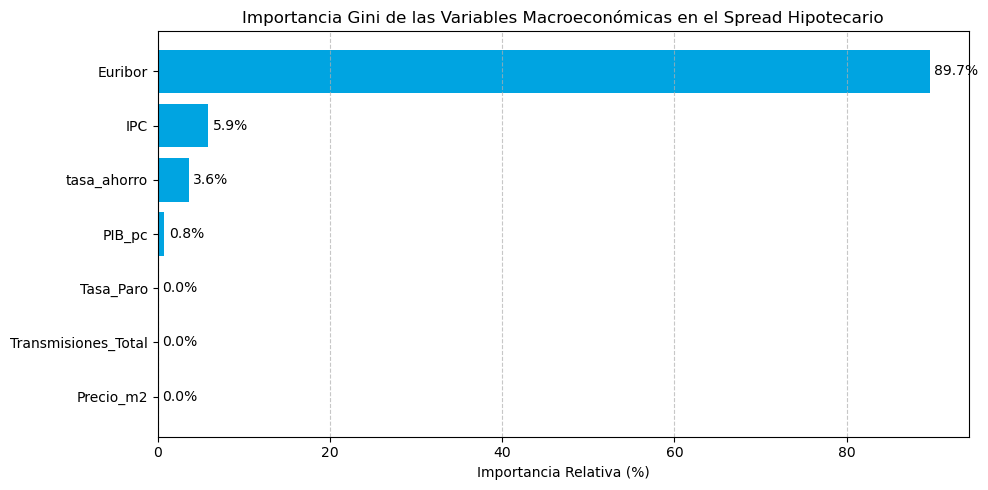

Interpretación:
La variable 'Euribor' domina históricamente el 89.7% del poder de recomendación algorítmica.


In [197]:
import matplotlib.pyplot as plt
import numpy as np

# Extraer importancias del modelo re-entrenado
importancias = gbm_model.feature_importances_
indices = np.argsort(importancias)[::-1]

names = [MACRO_FEATURES[i] for i in indices]
vals = importancias[indices] * 100 # A porcentaje

plt.figure(figsize=(10, 5))
plt.title("Importancia Gini de las Variables Macroeconómicas en el Spread Hipotecario")
bars = plt.barh(range(len(names)), vals[::-1], align="center", color="#00A4E1")
plt.yticks(range(len(names)), names[::-1])
plt.xlabel("Importancia Relativa (%)")
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Añadir etiquetas
for bar in bars:
    plt.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, 
             f'{bar.get_width():.1f}%', va='center', ha='left', fontsize=10)

plt.tight_layout()
plt.show()

print("Interpretación:")
print(f"La variable '{names[0]}' domina históricamente el {vals[0]:.1f}% del poder de recomendación algorítmica.")


## 12. Regulación Final: Maximización vs Ahogamiento Financiero (Búsqueda Binaria de Tope DTI)
El Algoritmo GBM nos devuelve lo que el Banco de manera predictiva "consideraría cobrar" dados los spreads comerciales de la época. No obstante, CaixaBank está supeditada al límite estricto normativo de sobreendeudamiento inter-bancario (**DTI < 35%**).

Sometemos el Euríbor Base + Diferencial de ML a un filtro con cota logarítmica (Búsqueda Binaria `O(log N)`). Si la ambición matemática de los árboles asfixia el ratio financiero de nuestro gestor del modelo (la mensualidad teórica liquida >35% del sueldo), el spread rebajará de forma forzada.

In [198]:
def simulate_custom_mortgage(target_year="2026", user_income=2500, user_loan=150000, user_months=300):
    target_year_int = int(target_year)
    target_year_str = str(target_year_int)

    contexto = []
    print(f"\n--- SIMULACIÓN ML: HIPOTECA AÑO {target_year_int} ---")
    for f in MACRO_FEATURES:
        if target_year_int <= 2024:
            subset = historico[historico['year_int'] == target_year_int][f]
            val = float(subset.mean()) if not subset.empty else _MACRO_FORECASTS[f]['last_real']
            if pd.isna(val):
                val = _MACRO_FORECASTS[f]['last_real']
        else:
            val = _MACRO_FORECASTS[f].get(target_year_str, _MACRO_FORECASTS[f]['last_real'])
        contexto.append(val)

    # CORRECCIÓN: Buscar el índice del Euríbor dinámicamente para evitar desastres matemáticos
    idx_euribor = MACRO_FEATURES.index('Euribor')
    euribor_base = contexto[idx_euribor]
    print(f"[MACRO] Euribor proyectado: {euribor_base:.3f}%")

    x_input = scaler_gb.transform([contexto])
    ml_spread_recomendado = max(float(gbm_model.predict(x_input)[0]), 0.1)
    tasa_bruta_ml = euribor_base + ml_spread_recomendado
    print(f"[PRICER ML] Interés bruto calculado por Árboles (Eur+Spread): {tasa_bruta_ml:.3f}%")

    # Calcular la cuota real que el banco le exigiría al cliente
    t_mensual_banco = (tasa_bruta_ml / 100) / 12.0
    cuota_banco = user_loan * t_mensual_banco * (1 + t_mensual_banco)**user_months / ((1 + t_mensual_banco)**user_months - 1)

    limite_cuota = user_income * 0.35
    tasa_dti_max = tasa_bruta_ml

    # Mantengo tu brillante algoritmo de búsqueda binaria para calcular el techo máximo
    if limite_cuota > 0 and user_loan > 0:
        lo, hi = 0.001, 0.25
        for _ in range(50):
            mid = (lo + hi) / 2.0
            t_mensual = mid / 12.0
            cuota_test = user_loan * t_mensual * (1 + t_mensual)**user_months / ((1 + t_mensual)**user_months - 1)
            if cuota_test <= limite_cuota:
                lo = mid
            else:
                hi = mid
        tasa_dti_max = round(lo * 100, 3)

    print(f"[RIESGOS] TIN Máximo absoluto soportable: {tasa_dti_max:.3f}% (Tope Cuota: {limite_cuota:.2f}€)")
    print(f"[RIESGOS] Cuota exigida por el modelo ML: {cuota_banco:.2f}€")

    # CORRECCIÓN BANCARIA: El banco no regala margen. Si no puede pagar, se deniega.
    if tasa_bruta_ml > tasa_dti_max:
        print(f"\n[RESOLUCIÓN] ❌ DENEGADA. La cuota ({cuota_banco:.2f}€) supera el DTI del 35% de los ingresos ({limite_cuota:.2f}€).")
        oferta_final = None
    else:
        oferta_final = tasa_bruta_ml
        print(f"\n===> OFERTA CLIENTE FORMALIZADA: {oferta_final:.3f}% TIN")

    return oferta_final

# Prueba la inferencia sobre el simulador:
simulate_custom_mortgage("2026", user_income=3000, user_loan=150000, user_months=360)


--- SIMULACIÓN ML: HIPOTECA AÑO 2026 ---
[MACRO] Euribor proyectado: 2.000%
[PRICER ML] Interés bruto calculado por Árboles (Eur+Spread): 3.492%
[RIESGOS] TIN Máximo absoluto soportable: 7.511% (Tope Cuota: 1050.00€)
[RIESGOS] Cuota exigida por el modelo ML: 672.93€

===> OFERTA CLIENTE FORMALIZADA: 3.492% TIN


3.492436967175254


--- SIMULACIÓN ML: HIPOTECA AÑO 2026 ---
[MACRO] Euribor proyectado: 2.000%
[PRICER ML] Interés bruto calculado por Árboles (Eur+Spread): 3.492%
[RIESGOS] TIN Máximo absoluto soportable: 7.511% (Tope Cuota: 1050.00€)
[RIESGOS] Cuota exigida por el modelo ML: 672.93€

===> ✅ OFERTA CLIENTE FORMALIZADA: 3.492% TIN


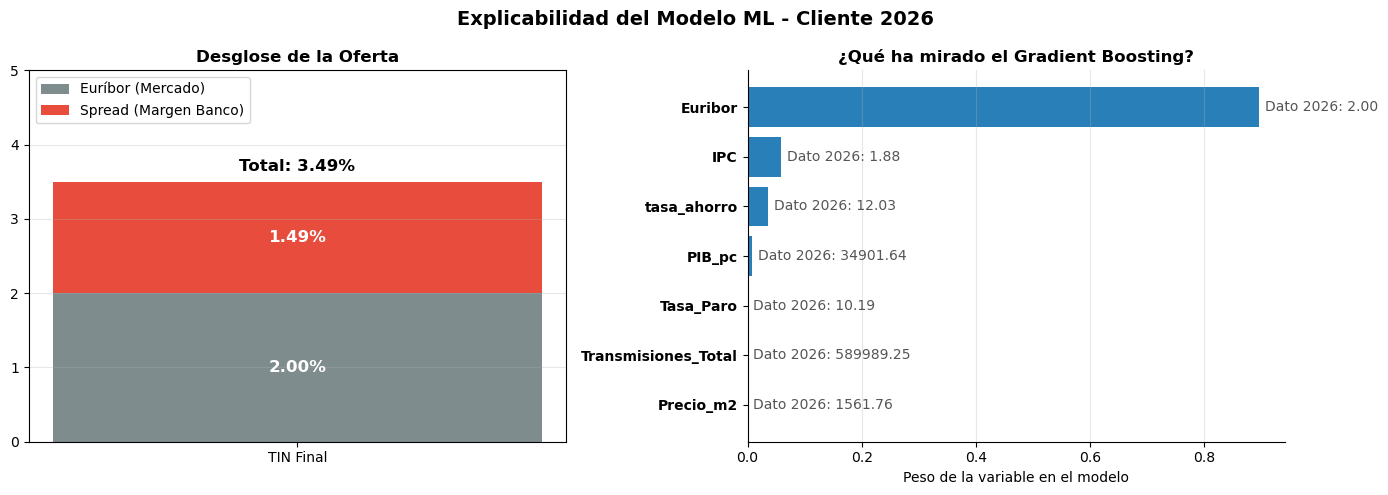

3.492436967175254

In [199]:
import matplotlib.pyplot as plt
import numpy as np

def simulate_custom_mortgage(target_year="2026", user_income=2500, user_loan=150000, user_months=300, plot_explanation=True):
    target_year_int = int(target_year)
    target_year_str = str(target_year_int)

    contexto = []
    print(f"\n--- SIMULACIÓN ML: HIPOTECA AÑO {target_year_int} ---")
    for f in MACRO_FEATURES:
        if target_year_int <= 2024:
            subset = historico[historico['year_int'] == target_year_int][f]
            val = float(subset.mean()) if not subset.empty else _MACRO_FORECASTS[f]['last_real']
            if pd.isna(val):
                val = _MACRO_FORECASTS[f]['last_real']
        else:
            val = _MACRO_FORECASTS[f].get(target_year_str, _MACRO_FORECASTS[f]['last_real'])
        contexto.append(val)

    # Buscar el índice del Euríbor dinámicamente para evitar desastres matemáticos
    idx_euribor = MACRO_FEATURES.index('Euribor')
    euribor_base = contexto[idx_euribor]
    print(f"[MACRO] Euribor proyectado: {euribor_base:.3f}%")

    x_input = scaler_gb.transform([contexto])
    ml_spread_recomendado = max(float(gbm_model.predict(x_input)[0]), 0.1)
    tasa_bruta_ml = euribor_base + ml_spread_recomendado
    print(f"[PRICER ML] Interés bruto calculado por Árboles (Eur+Spread): {tasa_bruta_ml:.3f}%")

    # Calcular la cuota real que el banco le exigiría al cliente
    t_mensual_banco = (tasa_bruta_ml / 100) / 12.0
    cuota_banco = user_loan * t_mensual_banco * (1 + t_mensual_banco)**user_months / ((1 + t_mensual_banco)**user_months - 1)

    limite_cuota = user_income * 0.35
    tasa_dti_max = tasa_bruta_ml

    # Algoritmo de búsqueda binaria para calcular el techo máximo
    if limite_cuota > 0 and user_loan > 0:
        lo, hi = 0.001, 0.25
        for _ in range(50):
            mid = (lo + hi) / 2.0
            t_mensual = mid / 12.0
            cuota_test = user_loan * t_mensual * (1 + t_mensual)**user_months / ((1 + t_mensual)**user_months - 1)
            if cuota_test <= limite_cuota:
                lo = mid
            else:
                hi = mid
        tasa_dti_max = round(lo * 100, 3)

    print(f"[RIESGOS] TIN Máximo absoluto soportable: {tasa_dti_max:.3f}% (Tope Cuota: {limite_cuota:.2f}€)")
    print(f"[RIESGOS] Cuota exigida por el modelo ML: {cuota_banco:.2f}€")

    # CORRECCIÓN BANCARIA: Resolución (Aprobada o Denegada)
    if tasa_bruta_ml > tasa_dti_max:
        print(f"\n[RESOLUCIÓN] ❌ DENEGADA. La cuota ({cuota_banco:.2f}€) supera el DTI del 35% de los ingresos ({limite_cuota:.2f}€).")
        oferta_final = None
    else:
        oferta_final = tasa_bruta_ml
        print(f"\n===> ✅ OFERTA CLIENTE FORMALIZADA: {oferta_final:.3f}% TIN")

    # =========================================================================
    # 📊 DASHBOARD DE EXPLICABILIDAD PARA EL TFM
    # =========================================================================
    if plot_explanation and oferta_final is not None:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle(f'Explicabilidad del Modelo ML - Cliente {target_year_int}', fontsize=14, fontweight='bold')

        # GRÁFICO 1: Composición del TIN (Stack Bar)
        ax1.bar(['TIN Final'], [euribor_base], color='#7F8C8D', label='Euríbor (Mercado)')
        ax1.bar(['TIN Final'], [ml_spread_recomendado], bottom=[euribor_base], color='#E74C3C', label='Spread (Margen Banco)')
        ax1.set_ylim(0, max(tasa_bruta_ml + 1.5, 5))
        ax1.set_title("Desglose de la Oferta", fontweight='bold')
        ax1.legend(loc='upper left')
        
        # Textos dentro de las barras
        ax1.text(0, euribor_base/2, f"{euribor_base:.2f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=12)
        ax1.text(0, euribor_base + (ml_spread_recomendado/2), f"{ml_spread_recomendado:.2f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=12)
        ax1.text(0, tasa_bruta_ml + 0.15, f"Total: {tasa_bruta_ml:.2f}%", ha='center', color='black', fontweight='bold', fontsize=12)

        # GRÁFICO 2: Importancia de las Variables con el valor actual
        importances = gbm_model.feature_importances_
        sorted_idx = np.argsort(importances)
        
        nombres_ordenados = [MACRO_FEATURES[i] for i in sorted_idx]
        importancias_ordenadas = importances[sorted_idx]
        valores_contexto = [contexto[i] for i in sorted_idx]

        y_pos = np.arange(len(MACRO_FEATURES))
        ax2.barh(y_pos, importancias_ordenadas, color='#2980B9')
        ax2.set_yticks(y_pos)
        ax2.set_yticklabels(nombres_ordenados, fontweight='bold')
        ax2.set_title('¿Qué ha mirado el Gradient Boosting?', fontweight='bold')
        ax2.set_xlabel('Peso de la variable en el modelo')

        # Escribir el valor real que tuvo la variable ese año
        for i, val in enumerate(valores_contexto):
            ax2.text(importancias_ordenadas[i] + 0.01, i, f"Dato {target_year_int}: {val:.2f}", va='center', color='#555555', fontsize=10)

        ax1.grid(axis='y', alpha=0.3)
        ax2.grid(axis='x', alpha=0.3)
        ax2.spines['top'].set_visible(False)
        ax2.spines['right'].set_visible(False)

        plt.tight_layout()
        plt.show()

    return oferta_final

# PRUEBA:
simulate_custom_mortgage("2026", user_income=3000, user_loan=150000, user_months=360)


--- SIMULACIÓN ML: HIPOTECA AÑO 2028 ---
[MACRO] Euribor proyectado: 2.300%
[PRICER ML] Interés bruto calculado por Árboles (Eur+Spread): 3.497%
[RIESGOS] TIN Máximo absoluto soportable: 7.511% (Tope Cuota: 1050.00€)
[RIESGOS] Cuota exigida por el modelo ML: 673.29€

===> ✅ OFERTA CLIENTE FORMALIZADA: 3.497% TIN


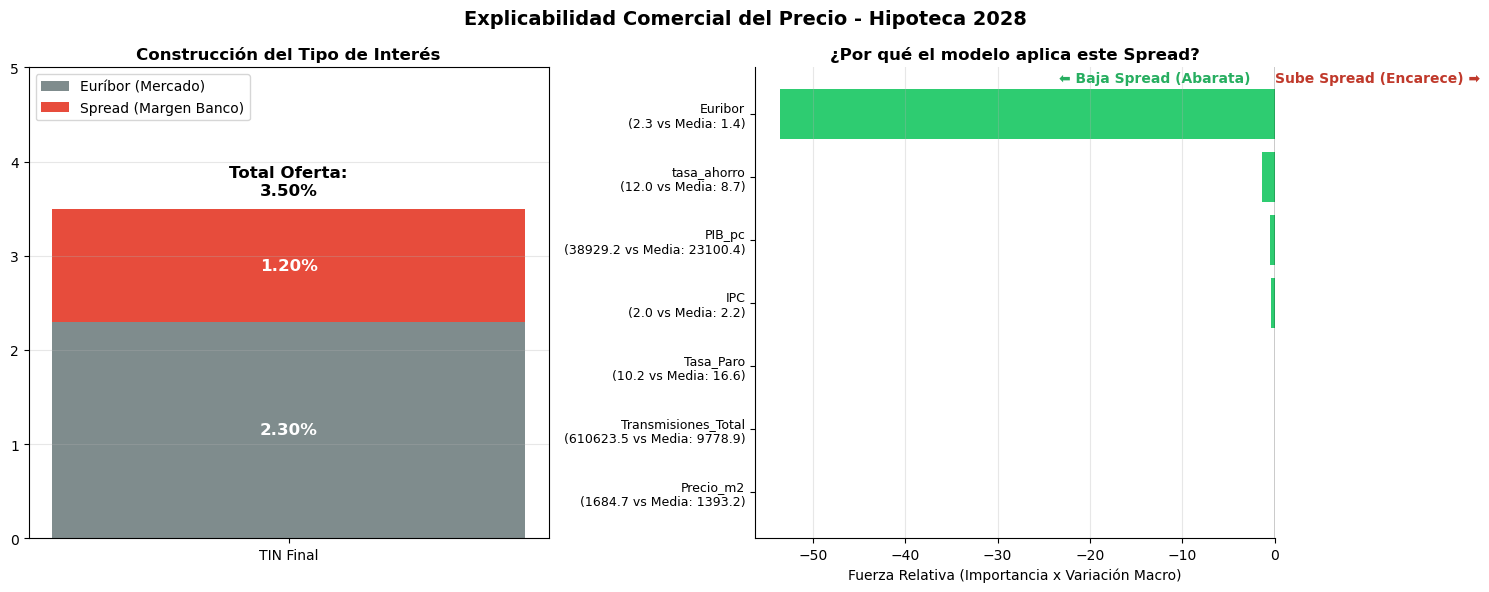

3.496690152551916

In [200]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def simulate_custom_mortgage(target_year="2026", user_income=2500, user_loan=150000, user_months=300, plot_explanation=True):
    target_year_int = int(target_year)
    target_year_str = str(target_year_int)

    contexto = []
    print(f"\n--- SIMULACIÓN ML: HIPOTECA AÑO {target_year_int} ---")
    for f in MACRO_FEATURES:
        if target_year_int <= 2024:
            subset = historico[historico['year_int'] == target_year_int][f]
            val = float(subset.mean()) if not subset.empty else _MACRO_FORECASTS[f]['last_real']
            if pd.isna(val):
                val = _MACRO_FORECASTS[f]['last_real']
        else:
            val = _MACRO_FORECASTS[f].get(target_year_str, _MACRO_FORECASTS[f]['last_real'])
        contexto.append(val)

    # Buscar el índice del Euríbor dinámicamente
    idx_euribor = MACRO_FEATURES.index('Euribor')
    euribor_base = contexto[idx_euribor]
    print(f"[MACRO] Euribor proyectado: {euribor_base:.3f}%")

    x_input = scaler_gb.transform([contexto])
    ml_spread_recomendado = max(float(gbm_model.predict(x_input)[0]), 0.1)
    tasa_bruta_ml = euribor_base + ml_spread_recomendado
    print(f"[PRICER ML] Interés bruto calculado por Árboles (Eur+Spread): {tasa_bruta_ml:.3f}%")

    # Calcular la cuota real que el banco le exigiría al cliente
    t_mensual_banco = (tasa_bruta_ml / 100) / 12.0
    cuota_banco = user_loan * t_mensual_banco * (1 + t_mensual_banco)**user_months / ((1 + t_mensual_banco)**user_months - 1)

    limite_cuota = user_income * 0.35
    tasa_dti_max = tasa_bruta_ml

    # Algoritmo de búsqueda binaria para calcular el techo máximo
    if limite_cuota > 0 and user_loan > 0:
        lo, hi = 0.001, 0.25
        for _ in range(50):
            mid = (lo + hi) / 2.0
            t_mensual = mid / 12.0
            cuota_test = user_loan * t_mensual * (1 + t_mensual)**user_months / ((1 + t_mensual)**user_months - 1)
            if cuota_test <= limite_cuota:
                lo = mid
            else:
                hi = mid
        tasa_dti_max = round(lo * 100, 3)

    print(f"[RIESGOS] TIN Máximo absoluto soportable: {tasa_dti_max:.3f}% (Tope Cuota: {limite_cuota:.2f}€)")
    print(f"[RIESGOS] Cuota exigida por el modelo ML: {cuota_banco:.2f}€")

    # CORRECCIÓN BANCARIA: Resolución (Aprobada o Denegada)
    if tasa_bruta_ml > tasa_dti_max:
        print(f"\n[RESOLUCIÓN] ❌ DENEGADA. La cuota ({cuota_banco:.2f}€) supera el DTI del 35% de los ingresos ({limite_cuota:.2f}€).")
        oferta_final = None
    else:
        oferta_final = tasa_bruta_ml
        print(f"\n===> ✅ OFERTA CLIENTE FORMALIZADA: {oferta_final:.3f}% TIN")

    # =========================================================================
    # 📊 DASHBOARD: EXPLICABILIDAD DEL SPREAD (Por qué la IA elige ese precio)
    # =========================================================================
    if plot_explanation and oferta_final is not None:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
        fig.suptitle(f'Explicabilidad Comercial del Precio - Hipoteca {target_year_int}', fontsize=14, fontweight='bold')

        # ---------------------------------------------------------
        # GRÁFICO 1: Composición del TIN (Stack Bar)
        # ---------------------------------------------------------
        ax1.bar(['TIN Final'], [euribor_base], color='#7F8C8D', label='Euríbor (Mercado)')
        ax1.bar(['TIN Final'], [ml_spread_recomendado], bottom=[euribor_base], color='#E74C3C', label='Spread (Margen Banco)')
        ax1.set_ylim(0, max(tasa_bruta_ml + 1.5, 5))
        ax1.set_title("Construcción del Tipo de Interés", fontweight='bold')
        ax1.legend(loc='upper left')
        
        ax1.text(0, euribor_base/2, f"{euribor_base:.2f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=12)
        ax1.text(0, euribor_base + (ml_spread_recomendado/2), f"{ml_spread_recomendado:.2f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=12)
        ax1.text(0, tasa_bruta_ml + 0.15, f"Total Oferta:\n{tasa_bruta_ml:.2f}%", ha='center', color='black', fontweight='bold', fontsize=12)

        # ---------------------------------------------------------
        # GRÁFICO 2: Fuerzas que empujan el Spread (Efecto Proxy)
        # ---------------------------------------------------------
        importances = gbm_model.feature_importances_
        
        # Diccionario de signos económicos esperados (1 = Sube Spread, -1 = Baja Spread)
        signos_economicos = {
            'Euribor': -1, 'Tasa_Paro': 1, 'PIB_pc': -1, 
            'IPC': 1, 'tasa_ahorro': -1, 'Precio_m2': 1
        }
        
        impactos = []
        nombres = []
        colores = []
        
        for i, f in enumerate(MACRO_FEATURES):
            # Comparamos el dato actual con la media histórica a la que está acostumbrado el banco
            media_hist = historico[f].mean()
            val_actual = contexto[i]
            
            # Variación porcentual respecto a lo "normal"
            variacion = (val_actual - media_hist) / (abs(media_hist) + 0.0001)
            
            # Multiplicamos por su importancia en el árbol y su dirección económica
            fuerza = variacion * signos_economicos.get(f, 1) * importances[i] * 100 
            impactos.append(fuerza)
            
            # Formateamos el texto del eje Y para que muestre los datos reales
            texto_var = f"{f}\n({val_actual:.1f} vs Media: {media_hist:.1f})"
            nombres.append(texto_var)
            
            # Verde si abarata (fuerza negativa), Rojo si encarece (fuerza positiva)
            colores.append('#E74C3C' if fuerza > 0 else '#2ECC71')

        # Ordenar de menor a mayor impacto visual
        idx_orden = np.argsort(np.abs(impactos))
        impactos_ord = np.array(impactos)[idx_orden]
        nombres_ord = np.array(nombres)[idx_orden]
        colores_ord = np.array(colores)[idx_orden]

        y_pos = np.arange(len(MACRO_FEATURES))
        ax2.barh(y_pos, impactos_ord, color=colores_ord)
        
        # Estética del gráfico de fuerzas
        ax2.set_yticks(y_pos)
        ax2.set_yticklabels(nombres_ord, fontsize=9)
        ax2.set_title('¿Por qué el modelo aplica este Spread?', fontweight='bold')
        ax2.set_xlabel('Fuerza Relativa (Importancia x Variación Macro)')
        ax2.axvline(0, color='black', linewidth=1)
        
        # Añadir etiquetas direccionales
        ax2.text(max(max(impactos_ord), 0.1)*0.05, len(MACRO_FEATURES)-0.5, 'Sube Spread (Encarece) ➡️', color='#C0392B', fontweight='bold', ha='left')
        ax2.text(min(min(impactos_ord), -0.1)*0.05, len(MACRO_FEATURES)-0.5, '⬅️ Baja Spread (Abarata)', color='#27AE60', fontweight='bold', ha='right')

        ax1.grid(axis='y', alpha=0.3)
        ax2.grid(axis='x', alpha=0.3)
        ax2.spines['top'].set_visible(False)
        ax2.spines['right'].set_visible(False)

        plt.tight_layout()
        plt.show()

    return oferta_final

# PRUEBA:
simulate_custom_mortgage("2028", user_income=3000, user_loan=150000, user_months=360)